## **01. 검증 목적**

기존 Actor-Critic 실험은 단일 랜덤 시드(Seed 42)를 기반으로 진행하였으므로, 해당 실험 결과가 다른 랜덤 시드에서도 일관되게 나타나는지 검증하고자 함.

이를 위해 엔트로피 보너스 계수 0.05를 적용한 실험 6-1과 엔트로피 보너스 계수 0.01을 적용한 추가 test를 대상으로, Seed 123과 Seed 2026에서 동일한 환경 및 학습 조건으로 추가 실험을 진행함.

기존 Seed 42의 실험 결과를 포함하여 총 3개의 랜덤 시드에서 주문 처리 성공률, 평균 보상, 메뉴별 성공률을 비교하고, 각 평가 지표의 평균과 표준편차를 분석하여 학습 성능의 재현성과 안정성을 검증하고자 함.

또한 엔트로피 보너스 계수 증가에 따른 탐색 강화와 주문 처리 성능의 개선이 특정 랜덤 시드에 의존하는 결과인지, 다른 랜덤 시드에서도 일관되게 나타나는 경향인지 확인하고자 함.

####
## **02. 실험 환경 및 공통 하이퍼파라미터**

랜덤 시드에 따른 학습 성능의 차이를 확인하기 위해 기존 Actor-Critic 실험 6-1 및 추가 test의 환경과 학습 조건을 동일하게 유지함.

### 2-1. 실험 환경

| 항목 | 설정 |
|---|---|
| 환경 | PizzaShopEnv |
| 메뉴 종류 | 4종 (치즈, 페퍼로니, 버섯, 스페셜) |
| 재료 종류 | 5종 (도우, 치즈, 페퍼로니, 버섯, 올리브) |
| 에피소드당 주문 수 (최대 주문 수) | 4개 |
| 행동 공간 | 7개 |
| 상태 공간 | 13차원 |
| 주문 제한 시간 | 36~48 steps |
| 최대 에피소드 길이 | 100 steps |
| 주문 처리 방식 | 전체 메뉴 기준 FIFO |
| 학습 장치 | CPU |

### 2-2. 보상 설정

| 항목 | 보상 |
|---|---:|
| 올바른 주문 처리 | +150 |
| 잘못된 주문 처리 | -15 |
| 주문 시간 초과 | -50 |
| 잘못된 재료 추가 | -2 |
| 매 스텝 | -0.1 |
| 올바른 재료 추가 (Reward Shaping) | +5 |
| 마지막 재료 추가 및 피자 완성 (Reward Shaping) | +10 |

### 2-3. 공통 하이퍼파라미터

| 항목 | 설정 |
|---|---|
| 알고리즘 | Actor-Critic |
| 은닉층 크기 | 256 |
| Learning Rate | 0.0002 |
| Gamma | 0.98 |
| 학습 방식 | 1-step TD |
| 업데이트 주기 | 10 transitions |
| Reward Scaling | 1/100 |
| 학습 에피소드 수 | 4,000 |
| 평가 에피소드 수 | 100 |
| 평가 주문 수 | 400 |

### 2-4. 검증 실험 조건

| 구분 | 엔트로피 보너스 계수 | 랜덤 시드 |
|---|---:|---|
| 실험 6 | 0.05 | 42, 123, 2026 |
| 추가 test | 0.01 | 42, 123, 2026 |

각 엔트로피 보너스 계수에 대해 학습 시드만 변경하여 학습을 진행하며, 나머지 환경 및 하이퍼파라미터는 동일하게 유지함.

기존 Seed 42의 실험 결과를 활용하고, Seed 123과 Seed 2026에서 각각 추가 학습을 진행하여 총 6개의 학습 결과를 비교·분석함. 별도 평가 시에는 동일한 평가 조건을 적용하여 학습 시드에 따른 성능 차이를 확인하고자 함.

####
## **03. 엔트로피 보너스 계수 0.05 검증 실험**

기존 Actor-Critic 실험에서 가장 높은 주문 처리 성공률을 기록한 실험 6-1의 설정을 기반으로, 랜덤 시드에 따른 학습 성능의 재현성과 안정성을 검증하고자 함.

엔트로피 보너스 계수 0.05, Reward Shaping(+5, +10), 학습 횟수 4,000에피소드를 포함한 기존 실험 환경 및 하이퍼파라미터를 동일하게 유지하고, 랜덤 시드만 변경하여 추가 실험을 진행함.

### 3-1. 실험 조건

| 실험 번호 | 학습 시드 | 평가 시드 | 엔트로피 계수 | 학습 에피소드 수 | 비고 |
|---|---:|---:|---:|---:|---|
| 실험 6-1 | 42 | 42 | 0.05 | 4,000 | 기존 실험 결과 활용 |
| 실험 6-2 | 123 | 42 | 0.05 | 4,000 | 추가 검증 |
| 실험 6-3 | 2026 | 42 | 0.05 | 4,000 | 추가 검증 |

학습 시드에 따른 성능 차이를 확인하기 위해 학습 시드만 변경하고, 평가 시드는 42로 고정하여 동일한 평가 조건에서 성능을 비교함.

### 3-2. 실험 6-1 (Seed 42)

기존 Actor-Critic 실험 6-1의 학습 및 평가 결과를 활용함.

| 평가 지표 | 결과 |
|---|---:|
| 마지막 100에피소드 주문 성공률 | 97.00% |
| 마지막 100에피소드 평균 보상 | 638.67 |
| 별도 평가 전체 성공률 | 94.00% |
| 치즈 피자 성공률 | 96.77% |
| 페퍼로니 피자 성공률 | 93.94% |
| 버섯 피자 성공률 | 89.22% |
| 스페셜 피자 성공률 | 96.23% |

### 3-3. 실험 6-2 (Seed 123)

기존 실험 6-1의 환경 및 하이퍼파라미터를 동일하게 유지하고, 학습 시드를 123으로 변경하여 모델을 초기화한 후 처음부터 학습을 진행함.

### 3-4. 실험 6-3 (Seed 2026)

기존 실험 6-1의 환경 및 하이퍼파라미터를 동일하게 유지하고, 학습 시드를 2026으로 변경하여 모델을 초기화한 후 처음부터 학습을 진행함.

####
## 3-2. 실험 6-1 (Seed 42)

Device: cpu
Checkpoint saved: episode 0 -> actor_critic_exp6_1_seed42_checkpoints/actor_critic_exp6_1_seed42_ep0.pth
Episode   50 | Avg Reward (50):  -261.18 | Success: 0 | Timeout: 4
Episode  100 | Avg Reward (50):  -267.54 | Success: 0 | Timeout: 4
Episode  150 | Avg Reward (50):  -245.78 | Success: 0 | Timeout: 4
Episode  200 | Avg Reward (50):  -228.34 | Success: 0 | Timeout: 4
Episode  250 | Avg Reward (50):  -223.25 | Success: 0 | Timeout: 4
Episode  300 | Avg Reward (50):  -187.32 | Success: 0 | Timeout: 4
Episode  350 | Avg Reward (50):  -188.67 | Success: 0 | Timeout: 4
Episode  400 | Avg Reward (50):  -155.12 | Success: 1 | Timeout: 3
Episode  450 | Avg Reward (50):  -140.83 | Success: 1 | Timeout: 3
Episode  500 | Avg Reward (50):  -158.86 | Success: 1 | Timeout: 3
Checkpoint saved: episode 500 -> actor_critic_exp6_1_seed42_checkpoints/actor_critic_exp6_1_seed42_ep500.pth
Episode  550 | Avg Reward (50):  -109.60 | Success: 0 | Timeout: 4
Episode  600 | Avg Reward (50):   -63

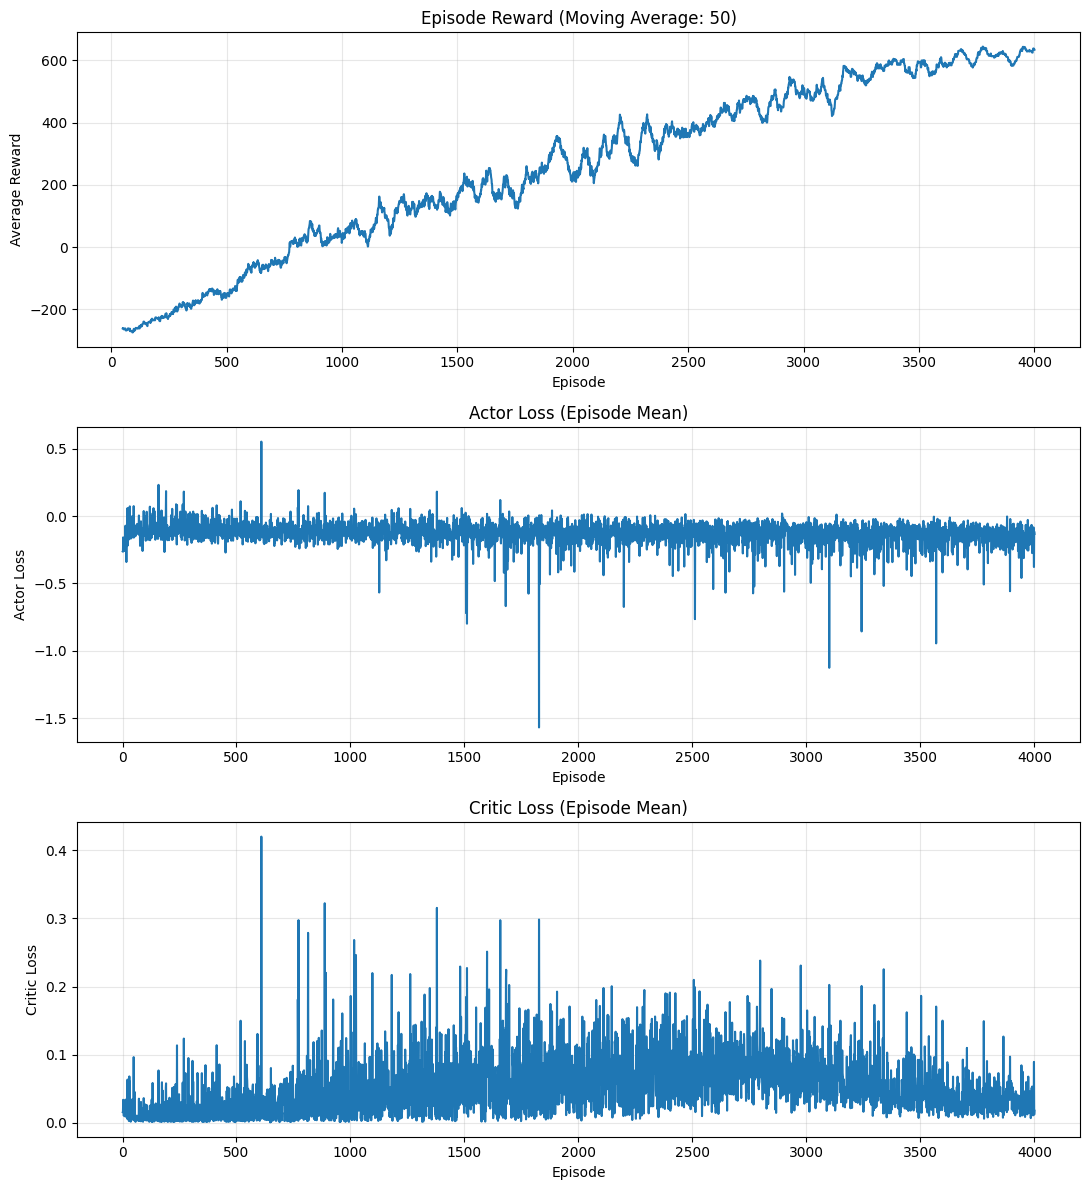

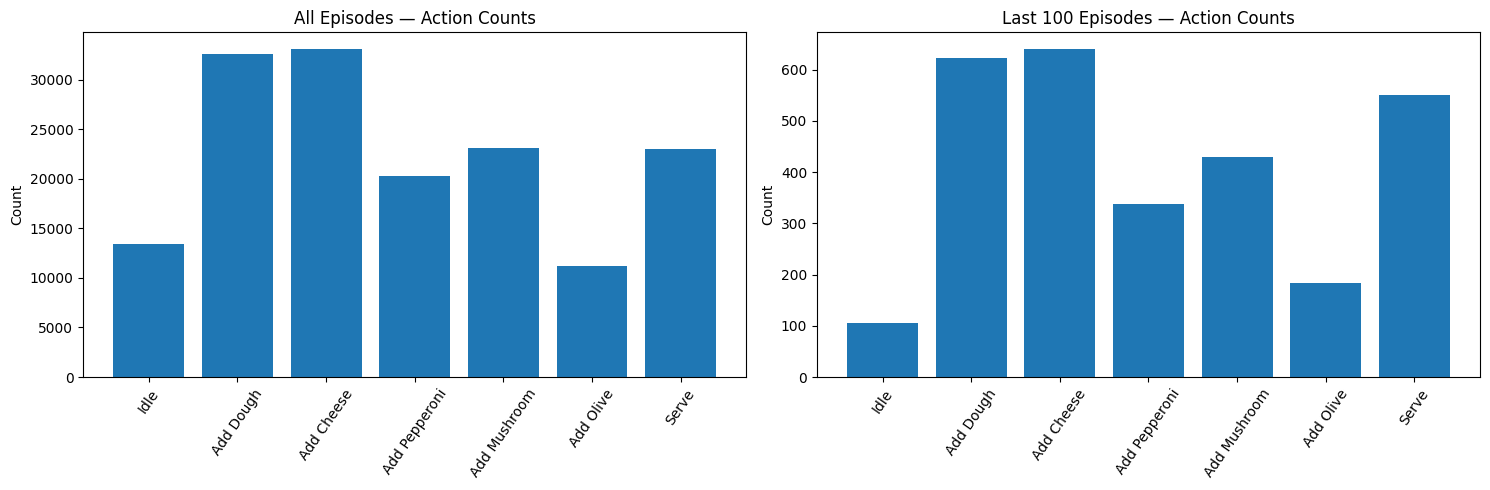

=== Last 100 Episodes Action Distribution ===
Idle            :   3.69%
Add Dough       :  21.69%
Add Cheese      :  22.32%
Add Pepperoni   :  11.73%
Add Mushroom    :  14.97%
Add Olive       :   6.41%
Serve           :  19.19%


In [ ]:
# 1. Imports & Hyperparameters
import random
import shutil
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym
from gymnasium import spaces
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.distributions import Categorical

SEED = 42
NUM_EPISODES = 4000 # ⭐ 학습 에피소드 2000 → 4000으로 증가
LEARNING_RATE = 0.0002
GAMMA = 0.98
N_ROLLOUT = 10
REWARD_SCALE = 100.0
ENTROPY_COEF = 0.05 # ⭐ 엔트로피 보너스 계수 0.01 → 0.05로 증가
SHAPING_REWARD = 5.0 # ⭐ 올바른 재료 추가 시 +5
COMPLETION_SHAPING_REWARD = 10.0 # ⭐ 주문에 필요한 마지막 재료를 추가하여 피자를 완성하면 +10

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

# 2. Pizza Shop Environment
class PizzaShopEnv(gym.Env):
    def __init__(self):
        super().__init__()
        self.max_orders = 4
        self.max_steps = 100
        self.menus = {
            1: [1, 1, 0, 0, 0],  # Cheese
            2: [1, 1, 1, 0, 0],  # Pepperoni
            3: [1, 1, 0, 1, 0],  # Mushroom
            4: [1, 1, 1, 1, 1],  # Special
        }
        # 0 Idle, 1 Dough, 2 Cheese, 3 Pepperoni, 4 Mushroom, 5 Olive, 6 Serve
        self.action_space = spaces.Discrete(7)
        self.observation_space = spaces.Box(
            low=np.zeros(13, dtype=np.float32),
            high=np.array([1, 1, 1, 1, 1, 4, 1, 4, 1, 4, 1, 4, 1], dtype=np.float32),
            dtype=np.float32,
        )
        self.counter = np.zeros(5, dtype=np.float32)
        self.orders = []
        self.steps = 0

    def _get_obs(self):
        obs = list(self.counter)
        for i in range(self.max_orders):
            if i < len(self.orders):
                obs.extend([self.orders[i]['menu'], self.orders[i]['timer'] / 48.0])
            else:
                obs.extend([0, 0])
        return np.array(obs, dtype=np.float32)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.counter = np.zeros(5, dtype=np.float32)
        self.orders = [
            {'menu': int(self.np_random.choice([1, 2, 3, 4])),
             'timer': int(self.np_random.integers(36, 49))}
            for _ in range(self.max_orders)
        ]
        self.steps = 0
        return self._get_obs(), {}

    def _next_required_ingredient(self):
        if not self.orders:
            return None
        expected = self.menus[self.orders[0]['menu']]
        for idx, needed in enumerate(expected):
            if needed == 1 and self.counter[idx] == 0:
                return idx
        return None

    def step(self, action):
        action = int(action)
        reward = -0.1
        success_count = 0
        timeout_count = 0
        self.steps += 1
        next_required = self._next_required_ingredient()

        if action == 0:
            pass
        elif action == 1:  # Dough
            if self.counter[0] == 0:
                self.counter[0] = 1
                if next_required == 0:
                    reward += (COMPLETION_SHAPING_REWARD
                               if np.array_equal(self.counter, self.menus[self.orders[0]['menu']])
                               else SHAPING_REWARD)
            else:
                reward -= 2
        elif action == 2:  # Cheese
            if self.counter[0] == 1 and self.counter[1] == 0:
                self.counter[1] = 1
                if next_required == 1:
                    reward += (COMPLETION_SHAPING_REWARD
                               if np.array_equal(self.counter, self.menus[self.orders[0]['menu']])
                               else SHAPING_REWARD)
            else:
                reward -= 2
        elif action in (3, 4, 5):  # Toppings
            idx = action - 1
            if self.counter[0] == 1 and self.counter[1] == 1 and self.counter[idx] == 0:
                self.counter[idx] = 1
                if next_required == idx:
                    reward += (COMPLETION_SHAPING_REWARD
                               if np.array_equal(self.counter, self.menus[self.orders[0]['menu']])
                               else SHAPING_REWARD)
            else:
                reward -= 2
        elif action == 6:  # Serve (FIFO)
            if self.orders:
                expected = self.menus[self.orders[0]['menu']]
                if np.array_equal(self.counter, expected):
                    reward += 150
                    success_count += 1
                    self.orders.pop(0)
                else:
                    reward -= 15
                self.counter = np.zeros(5, dtype=np.float32)

        # Every active order loses one step, including on a serve action.
        for order in self.orders:
            order['timer'] -= 1
        remaining = []
        for order in self.orders:
            if order['timer'] <= 0:
                reward -= 50
                timeout_count += 1
            else:
                remaining.append(order)
        self.orders = remaining

        terminated = len(self.orders) == 0
        truncated = self.steps >= self.max_steps and not terminated
        info = {'success_count': success_count, 'timeout_count': timeout_count}
        return self._get_obs(), reward, terminated, truncated, info

# 3. Shared-Network Actor-Critic
class ActorCritic(nn.Module):
    def __init__(self, state_dim=13, action_dim=7):
        super().__init__()
        self.data = []
        self.fc1 = nn.Linear(state_dim, 256)
        self.fc_pi = nn.Linear(256, action_dim)
        self.fc_v = nn.Linear(256, 1)
        self.optimizer = optim.Adam(self.parameters(), lr=LEARNING_RATE)

    def pi(self, x, softmax_dim=-1):
        x = F.relu(self.fc1(x))
        return F.softmax(self.fc_pi(x), dim=softmax_dim)

    def v(self, x):
        x = F.relu(self.fc1(x))
        return self.fc_v(x)

    def put_data(self, transition):
        self.data.append(transition)

    def make_batch(self):
        s_lst, a_lst, r_lst, s_prime_lst, terminal_lst = [], [], [], [], []
        for s, a, r, s_prime, terminated in self.data:
            s_lst.append(s)
            a_lst.append([a])
            r_lst.append([r / REWARD_SCALE])
            s_prime_lst.append(s_prime)
            terminal_lst.append([0.0 if terminated else 1.0])
        self.data = []
        s = torch.as_tensor(np.asarray(s_lst), dtype=torch.float32, device=device)
        a = torch.as_tensor(a_lst, dtype=torch.long, device=device)
        r = torch.as_tensor(r_lst, dtype=torch.float32, device=device)
        s_prime = torch.as_tensor(np.asarray(s_prime_lst), dtype=torch.float32, device=device)
        mask = torch.as_tensor(terminal_lst, dtype=torch.float32, device=device)
        return s, a, r, s_prime, mask

    def train_net(self):
        if not self.data:
            return None, None
        s, a, r, s_prime, mask = self.make_batch()
        # 10개 전이를 모아도 TD target은 각 전이에 대한 1-step target임
        with torch.no_grad():
            td_target = r + GAMMA * self.v(s_prime) * mask
        value = self.v(s)
        delta = td_target - value
        pi = self.pi(s, softmax_dim=1)
        pi_a = pi.gather(1, a).clamp_min(1e-8)
        entropy = Categorical(probs=pi).entropy().mean()
        actor_loss = (-torch.log(pi_a) * delta.detach()).mean() - ENTROPY_COEF * entropy
        critic_loss = F.smooth_l1_loss(value, td_target)
        loss = actor_loss + critic_loss

        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()
        return actor_loss.mean().item(), critic_loss.item()

# 4. Initialize & Checkpoint Setup
env = PizzaShopEnv()
env.reset(seed=SEED)
model = ActorCritic().to(device)
CHECKPOINT_DIR = Path('actor_critic_exp6_1_seed42_checkpoints')
CHECKPOINT_DIR.mkdir(exist_ok=True)

def save_checkpoint(episode):
    path = CHECKPOINT_DIR / f'actor_critic_exp6_1_seed42_ep{episode}.pth'
    torch.save(model.state_dict(), path)
    print(f'Checkpoint saved: episode {episode} -> {path}')

save_checkpoint(0)

# 5. Training — 10-transition mini-batches, 1-step TD
# Gymnasium: terminated는 진짜 종료, truncated는 시간 제한 종료.
# truncated에서는 에피소드를 멈추되 TD target의 다음 상태 가치는 bootstrap 가능하도록 유지.
episode_rewards, episode_successes, episode_timeouts = [], [], []
episode_actor_losses, episode_critic_losses = [], []
action_counts = np.zeros(7, dtype=np.int64)
all_episode_actions = []

for episode in range(1, NUM_EPISODES + 1):
    state, _ = env.reset()
    done = False
    total_reward, successes, timeouts = 0.0, 0, 0
    actor_losses, critic_losses, actions_this_episode = [], [], []

    while not done:
        for t in range(N_ROLLOUT):
            with torch.no_grad():
                state_tensor = torch.as_tensor(state, dtype=torch.float32, device=device)
                probs = model.pi(state_tensor)
                action = int(Categorical(probs).sample().item())

            next_state, reward, terminated, truncated, info = env.step(action)
            model.put_data((state, action, reward, next_state, terminated))
            action_counts[action] += 1
            actions_this_episode.append(action)
            total_reward += reward  # 보고용 점수는 원래 보상 단위로 기록
            successes += info['success_count']
            timeouts += info['timeout_count']
            state = next_state
            done = terminated or truncated
            if done:
                break

        actor_loss, critic_loss = model.train_net()
        if actor_loss is not None:
            actor_losses.append(actor_loss)
            critic_losses.append(critic_loss)

    episode_rewards.append(total_reward)
    episode_successes.append(successes)
    episode_timeouts.append(timeouts)
    episode_actor_losses.append(float(np.mean(actor_losses)))
    episode_critic_losses.append(float(np.mean(critic_losses)))
    all_episode_actions.append(actions_this_episode)

    if episode % 50 == 0:
        print(f'Episode {episode:4d} | Avg Reward (50): {np.mean(episode_rewards[-50:]):8.2f} '
              f'| Success: {successes} | Timeout: {timeouts}')
    if episode in (500, 1000, 2000, 3000, 4000):
        save_checkpoint(episode)

last_100_action_counts = np.zeros(7, dtype=np.int64)
for actions in all_episode_actions[-100:]:
    for a in actions:
        last_100_action_counts[a] += 1

# 6. Results
last_100_success = sum(episode_successes[-100:])
last_100_timeout = sum(episode_timeouts[-100:])
last_100_orders = last_100_success + last_100_timeout
total_success = sum(episode_successes)
total_timeout = sum(episode_timeouts)
total_orders = total_success + total_timeout

print('=== Actor-Critic Experiment 6-1 (Seed 42, Entropy 0.05, 4000 Episodes, Reward Shaping +5 / Completion +10) ===')
print(f'Last 100 Episodes Average Reward: {np.mean(episode_rewards[-100:]):.2f}')
print(f'Last 50 Episodes Average Reward: {np.mean(episode_rewards[-50:]):.2f}')
print(f'Overall Success: {total_success}/{total_orders} ({100*total_success/total_orders if total_orders else 0:.2f}%)')
print(f'Overall Timeout: {total_timeout}/{total_orders} ({100*total_timeout/total_orders if total_orders else 0:.2f}%)')
print(f'Last 100 Episodes Order Success Rate: {last_100_success}/{last_100_orders} ({100*last_100_success/last_100_orders if last_100_orders else 0:.2f}%)')
print(f'Last 100 Episodes Average Actor Loss: {np.mean(episode_actor_losses[-100:]):.4f}')
print(f'Last 100 Episodes Average Critic Loss: {np.mean(episode_critic_losses[-100:]):.4f}')

# 7. Learning Curves
def moving_average(values, window=50):
    return np.convolve(np.asarray(values, dtype=np.float64), np.ones(window) / window, mode='valid')

fig, axes = plt.subplots(3, 1, figsize=(11, 12))
axes[0].plot(np.arange(50, NUM_EPISODES + 1), moving_average(episode_rewards, 50))
axes[0].set_title('Episode Reward (Moving Average: 50)')
axes[0].set_xlabel('Episode')
axes[0].set_ylabel('Average Reward')
axes[1].plot(range(1, NUM_EPISODES + 1), episode_actor_losses)
axes[1].set_title('Actor Loss (Episode Mean)')
axes[1].set_xlabel('Episode')
axes[1].set_ylabel('Actor Loss')
axes[2].plot(range(1, NUM_EPISODES + 1), episode_critic_losses)
axes[2].set_title('Critic Loss (Episode Mean)')
axes[2].set_xlabel('Episode')
axes[2].set_ylabel('Critic Loss')
for ax in axes: ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 8. Action Distribution
names = ['Idle', 'Add Dough', 'Add Cheese', 'Add Pepperoni',
         'Add Mushroom', 'Add Olive', 'Serve']
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].bar(names, action_counts)
axes[0].set_title('All Episodes — Action Counts')
axes[0].set_ylabel('Count')
axes[1].bar(names, last_100_action_counts)
axes[1].set_title('Last 100 Episodes — Action Counts')
axes[1].set_ylabel('Count')
for ax in axes: ax.tick_params(axis='x', rotation=55)
plt.tight_layout()
plt.show()

last_total = last_100_action_counts.sum()
print('=== Last 100 Episodes Action Distribution ===')
for name, count in zip(names, last_100_action_counts):
    print(f'{name:16s}: {100*count/last_total if last_total else 0:6.2f}%')

#### **실험 6-1 결과 분석 (Seed 42)**
기존 Actor-Critic 실험 6-1의 학습 코드 및 실행 결과를 활용함. 해당 실험 결과를 시드별 학습 성능 비교를 위한 기준으로 사용함.

####
## 3-3. 실험 6-2 (Seed 123)

Device: cpu
Checkpoint saved: episode 0 -> actor_critic_exp6_2_seed123_checkpoints/actor_critic_exp6_2_seed123_ep0.pth
Episode   50 | Avg Reward (50):  -264.96 | Success: 1 | Timeout: 3
Episode  100 | Avg Reward (50):  -238.37 | Success: 0 | Timeout: 4
Episode  150 | Avg Reward (50):  -219.30 | Success: 0 | Timeout: 4
Episode  200 | Avg Reward (50):  -186.81 | Success: 1 | Timeout: 3
Episode  250 | Avg Reward (50):  -177.39 | Success: 2 | Timeout: 2
Episode  300 | Avg Reward (50):  -169.85 | Success: 1 | Timeout: 3
Episode  350 | Avg Reward (50):  -127.68 | Success: 0 | Timeout: 4
Episode  400 | Avg Reward (50):  -156.09 | Success: 1 | Timeout: 3
Episode  450 | Avg Reward (50):  -109.22 | Success: 1 | Timeout: 3
Episode  500 | Avg Reward (50):  -133.40 | Success: 2 | Timeout: 2
Checkpoint saved: episode 500 -> actor_critic_exp6_2_seed123_checkpoints/actor_critic_exp6_2_seed123_ep500.pth
Episode  550 | Avg Reward (50):  -110.46 | Success: 0 | Timeout: 4
Episode  600 | Avg Reward (50):  

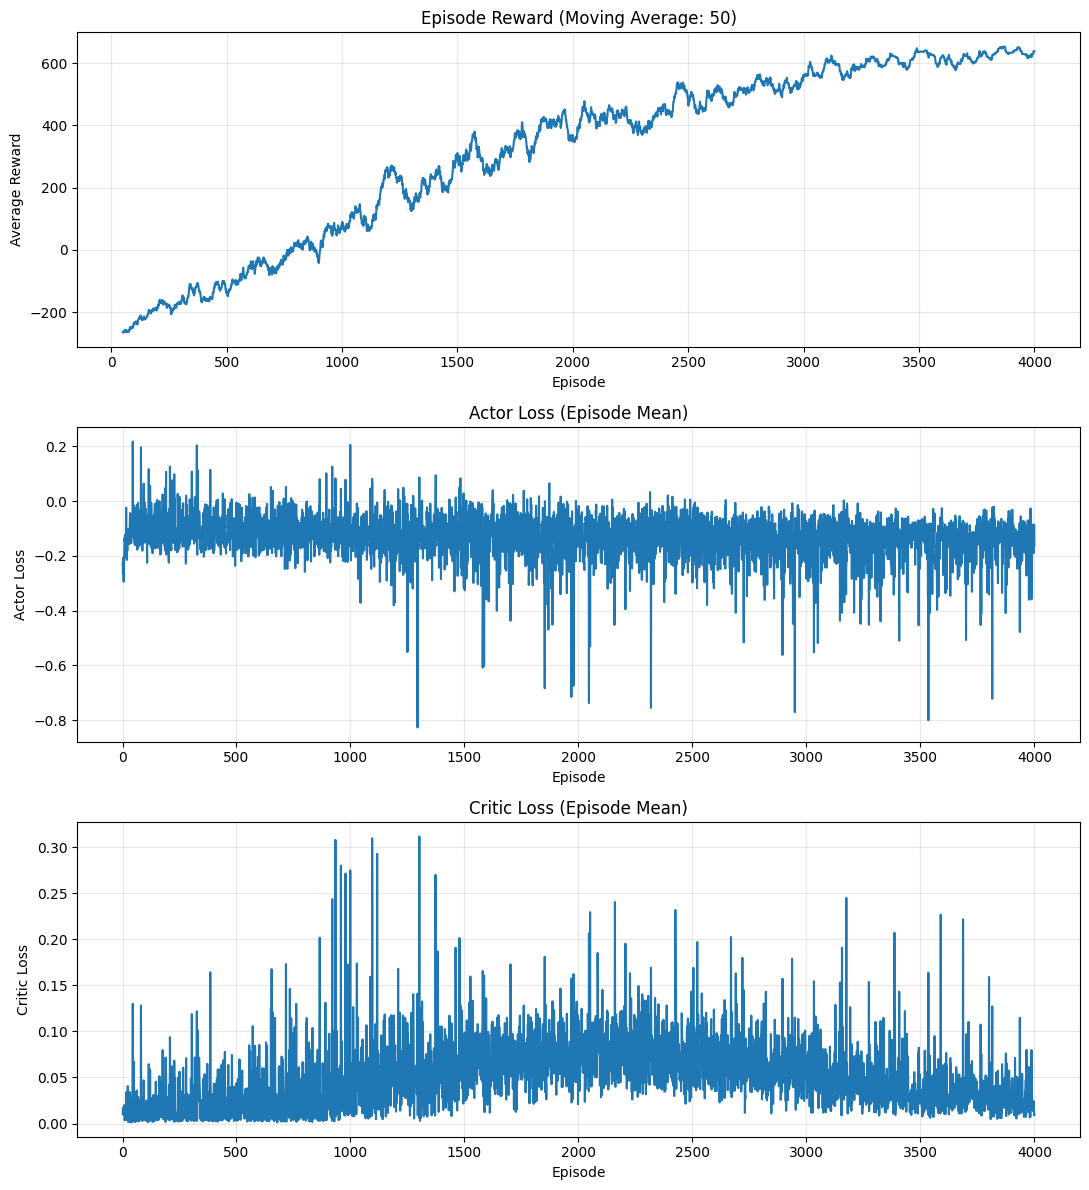

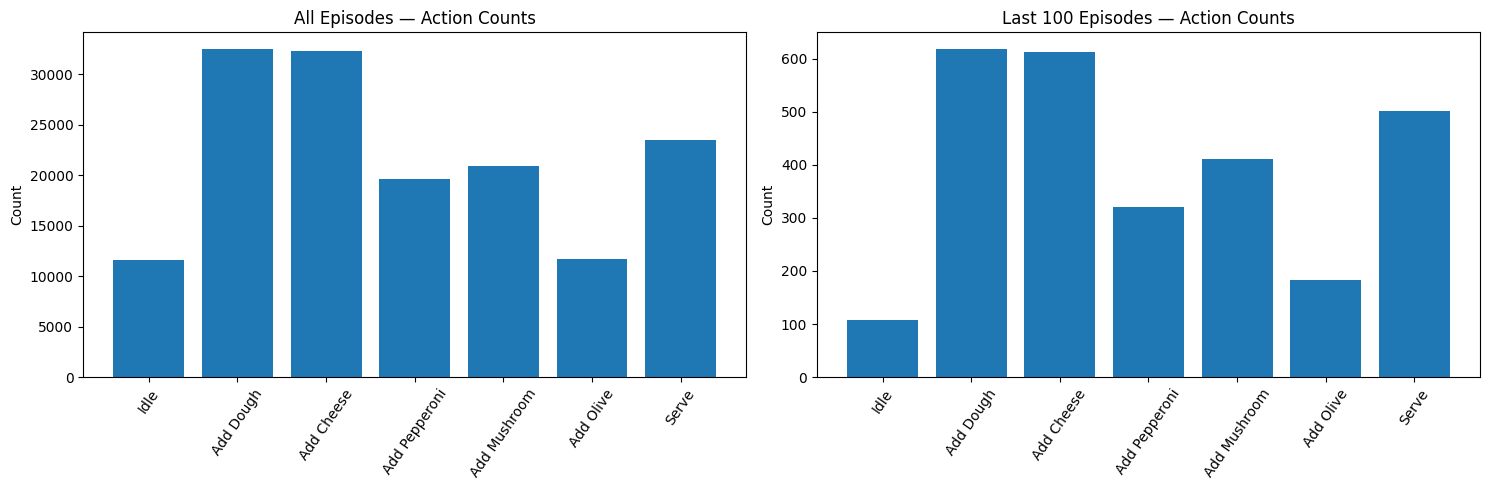

=== Last 100 Episodes Action Distribution ===
Idle            :   3.92%
Add Dough       :  22.47%
Add Cheese      :  22.21%
Add Pepperoni   :  11.62%
Add Mushroom    :  14.92%
Add Olive       :   6.64%
Serve           :  18.22%


In [ ]:
# 1. Imports & Hyperparameters
import random
import shutil
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym
from gymnasium import spaces
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.distributions import Categorical

SEED = 123
NUM_EPISODES = 4000 # ⭐ 학습 에피소드 2000 → 4000으로 증가
LEARNING_RATE = 0.0002
GAMMA = 0.98
N_ROLLOUT = 10
REWARD_SCALE = 100.0
ENTROPY_COEF = 0.05 # ⭐ 엔트로피 보너스 계수 0.01 → 0.05로 증가
SHAPING_REWARD = 5.0 # ⭐ 올바른 재료 추가 시 +5
COMPLETION_SHAPING_REWARD = 10.0 # ⭐ 주문에 필요한 마지막 재료를 추가하여 피자를 완성하면 +10

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

# 2. Pizza Shop Environment
class PizzaShopEnv(gym.Env):
    def __init__(self):
        super().__init__()
        self.max_orders = 4
        self.max_steps = 100
        self.menus = {
            1: [1, 1, 0, 0, 0],  # Cheese
            2: [1, 1, 1, 0, 0],  # Pepperoni
            3: [1, 1, 0, 1, 0],  # Mushroom
            4: [1, 1, 1, 1, 1],  # Special
        }
        # 0 Idle, 1 Dough, 2 Cheese, 3 Pepperoni, 4 Mushroom, 5 Olive, 6 Serve
        self.action_space = spaces.Discrete(7)
        self.observation_space = spaces.Box(
            low=np.zeros(13, dtype=np.float32),
            high=np.array([1, 1, 1, 1, 1, 4, 1, 4, 1, 4, 1, 4, 1], dtype=np.float32),
            dtype=np.float32,
        )
        self.counter = np.zeros(5, dtype=np.float32)
        self.orders = []
        self.steps = 0

    def _get_obs(self):
        obs = list(self.counter)
        for i in range(self.max_orders):
            if i < len(self.orders):
                obs.extend([self.orders[i]['menu'], self.orders[i]['timer'] / 48.0])
            else:
                obs.extend([0, 0])
        return np.array(obs, dtype=np.float32)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.counter = np.zeros(5, dtype=np.float32)
        self.orders = [
            {'menu': int(self.np_random.choice([1, 2, 3, 4])),
             'timer': int(self.np_random.integers(36, 49))}
            for _ in range(self.max_orders)
        ]
        self.steps = 0
        return self._get_obs(), {}

    def _next_required_ingredient(self):
        if not self.orders:
            return None
        expected = self.menus[self.orders[0]['menu']]
        for idx, needed in enumerate(expected):
            if needed == 1 and self.counter[idx] == 0:
                return idx
        return None

    def step(self, action):
        action = int(action)
        reward = -0.1
        success_count = 0
        timeout_count = 0
        self.steps += 1
        next_required = self._next_required_ingredient()

        if action == 0:
            pass
        elif action == 1:  # Dough
            if self.counter[0] == 0:
                self.counter[0] = 1
                if next_required == 0:
                    reward += (COMPLETION_SHAPING_REWARD
                               if np.array_equal(self.counter, self.menus[self.orders[0]['menu']])
                               else SHAPING_REWARD)
            else:
                reward -= 2
        elif action == 2:  # Cheese
            if self.counter[0] == 1 and self.counter[1] == 0:
                self.counter[1] = 1
                if next_required == 1:
                    reward += (COMPLETION_SHAPING_REWARD
                               if np.array_equal(self.counter, self.menus[self.orders[0]['menu']])
                               else SHAPING_REWARD)
            else:
                reward -= 2
        elif action in (3, 4, 5):  # Toppings
            idx = action - 1
            if self.counter[0] == 1 and self.counter[1] == 1 and self.counter[idx] == 0:
                self.counter[idx] = 1
                if next_required == idx:
                    reward += (COMPLETION_SHAPING_REWARD
                               if np.array_equal(self.counter, self.menus[self.orders[0]['menu']])
                               else SHAPING_REWARD)
            else:
                reward -= 2
        elif action == 6:  # Serve (FIFO)
            if self.orders:
                expected = self.menus[self.orders[0]['menu']]
                if np.array_equal(self.counter, expected):
                    reward += 150
                    success_count += 1
                    self.orders.pop(0)
                else:
                    reward -= 15
                self.counter = np.zeros(5, dtype=np.float32)

        # Every active order loses one step, including on a serve action.
        for order in self.orders:
            order['timer'] -= 1
        remaining = []
        for order in self.orders:
            if order['timer'] <= 0:
                reward -= 50
                timeout_count += 1
            else:
                remaining.append(order)
        self.orders = remaining

        terminated = len(self.orders) == 0
        truncated = self.steps >= self.max_steps and not terminated
        info = {'success_count': success_count, 'timeout_count': timeout_count}
        return self._get_obs(), reward, terminated, truncated, info

# 3. Shared-Network Actor-Critic
class ActorCritic(nn.Module):
    def __init__(self, state_dim=13, action_dim=7):
        super().__init__()
        self.data = []
        self.fc1 = nn.Linear(state_dim, 256)
        self.fc_pi = nn.Linear(256, action_dim)
        self.fc_v = nn.Linear(256, 1)
        self.optimizer = optim.Adam(self.parameters(), lr=LEARNING_RATE)

    def pi(self, x, softmax_dim=-1):
        x = F.relu(self.fc1(x))
        return F.softmax(self.fc_pi(x), dim=softmax_dim)

    def v(self, x):
        x = F.relu(self.fc1(x))
        return self.fc_v(x)

    def put_data(self, transition):
        self.data.append(transition)

    def make_batch(self):
        s_lst, a_lst, r_lst, s_prime_lst, terminal_lst = [], [], [], [], []
        for s, a, r, s_prime, terminated in self.data:
            s_lst.append(s)
            a_lst.append([a])
            r_lst.append([r / REWARD_SCALE])
            s_prime_lst.append(s_prime)
            terminal_lst.append([0.0 if terminated else 1.0])
        self.data = []
        s = torch.as_tensor(np.asarray(s_lst), dtype=torch.float32, device=device)
        a = torch.as_tensor(a_lst, dtype=torch.long, device=device)
        r = torch.as_tensor(r_lst, dtype=torch.float32, device=device)
        s_prime = torch.as_tensor(np.asarray(s_prime_lst), dtype=torch.float32, device=device)
        mask = torch.as_tensor(terminal_lst, dtype=torch.float32, device=device)
        return s, a, r, s_prime, mask

    def train_net(self):
        if not self.data:
            return None, None
        s, a, r, s_prime, mask = self.make_batch()
        # 10개 전이를 모아도 TD target은 각 전이에 대한 1-step target임
        with torch.no_grad():
            td_target = r + GAMMA * self.v(s_prime) * mask
        value = self.v(s)
        delta = td_target - value
        pi = self.pi(s, softmax_dim=1)
        pi_a = pi.gather(1, a).clamp_min(1e-8)
        entropy = Categorical(probs=pi).entropy().mean()
        actor_loss = (-torch.log(pi_a) * delta.detach()).mean() - ENTROPY_COEF * entropy
        critic_loss = F.smooth_l1_loss(value, td_target)
        loss = actor_loss + critic_loss

        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()
        return actor_loss.mean().item(), critic_loss.item()

# 4. Initialize & Checkpoint Setup
env = PizzaShopEnv()
env.reset(seed=SEED)
model = ActorCritic().to(device)
CHECKPOINT_DIR = Path('actor_critic_exp6_2_seed123_checkpoints')
CHECKPOINT_DIR.mkdir(exist_ok=True)

def save_checkpoint(episode):
    path = CHECKPOINT_DIR / f'actor_critic_exp6_2_seed123_ep{episode}.pth'
    torch.save(model.state_dict(), path)
    print(f'Checkpoint saved: episode {episode} -> {path}')

save_checkpoint(0)

# 5. Training — 10-transition mini-batches, 1-step TD
# Gymnasium: terminated는 진짜 종료, truncated는 시간 제한 종료.
# truncated에서는 에피소드를 멈추되 TD target의 다음 상태 가치는 bootstrap 가능하도록 유지.
episode_rewards, episode_successes, episode_timeouts = [], [], []
episode_actor_losses, episode_critic_losses = [], []
action_counts = np.zeros(7, dtype=np.int64)
all_episode_actions = []

for episode in range(1, NUM_EPISODES + 1):
    state, _ = env.reset()
    done = False
    total_reward, successes, timeouts = 0.0, 0, 0
    actor_losses, critic_losses, actions_this_episode = [], [], []

    while not done:
        for t in range(N_ROLLOUT):
            with torch.no_grad():
                state_tensor = torch.as_tensor(state, dtype=torch.float32, device=device)
                probs = model.pi(state_tensor)
                action = int(Categorical(probs).sample().item())

            next_state, reward, terminated, truncated, info = env.step(action)
            model.put_data((state, action, reward, next_state, terminated))
            action_counts[action] += 1
            actions_this_episode.append(action)
            total_reward += reward  # 보고용 점수는 원래 보상 단위로 기록
            successes += info['success_count']
            timeouts += info['timeout_count']
            state = next_state
            done = terminated or truncated
            if done:
                break

        actor_loss, critic_loss = model.train_net()
        if actor_loss is not None:
            actor_losses.append(actor_loss)
            critic_losses.append(critic_loss)

    episode_rewards.append(total_reward)
    episode_successes.append(successes)
    episode_timeouts.append(timeouts)
    episode_actor_losses.append(float(np.mean(actor_losses)))
    episode_critic_losses.append(float(np.mean(critic_losses)))
    all_episode_actions.append(actions_this_episode)

    if episode % 50 == 0:
        print(f'Episode {episode:4d} | Avg Reward (50): {np.mean(episode_rewards[-50:]):8.2f} '
              f'| Success: {successes} | Timeout: {timeouts}')
    if episode in (500, 1000, 2000, 3000, 4000):
        save_checkpoint(episode)

last_100_action_counts = np.zeros(7, dtype=np.int64)
for actions in all_episode_actions[-100:]:
    for a in actions:
        last_100_action_counts[a] += 1

# 6. Results
last_100_success = sum(episode_successes[-100:])
last_100_timeout = sum(episode_timeouts[-100:])
last_100_orders = last_100_success + last_100_timeout
total_success = sum(episode_successes)
total_timeout = sum(episode_timeouts)
total_orders = total_success + total_timeout

print('=== Actor-Critic Experiment 6-2 (Seed 123, Entropy 0.05, 4000 Episodes, Reward Shaping +5 / Completion +10) ===')
print(f'Last 100 Episodes Average Reward: {np.mean(episode_rewards[-100:]):.2f}')
print(f'Last 50 Episodes Average Reward: {np.mean(episode_rewards[-50:]):.2f}')
print(f'Overall Success: {total_success}/{total_orders} ({100*total_success/total_orders if total_orders else 0:.2f}%)')
print(f'Overall Timeout: {total_timeout}/{total_orders} ({100*total_timeout/total_orders if total_orders else 0:.2f}%)')
print(f'Last 100 Episodes Order Success Rate: {last_100_success}/{last_100_orders} ({100*last_100_success/last_100_orders if last_100_orders else 0:.2f}%)')
print(f'Last 100 Episodes Average Actor Loss: {np.mean(episode_actor_losses[-100:]):.4f}')
print(f'Last 100 Episodes Average Critic Loss: {np.mean(episode_critic_losses[-100:]):.4f}')

# 7. Learning Curves
def moving_average(values, window=50):
    return np.convolve(np.asarray(values, dtype=np.float64), np.ones(window) / window, mode='valid')

fig, axes = plt.subplots(3, 1, figsize=(11, 12))
axes[0].plot(np.arange(50, NUM_EPISODES + 1), moving_average(episode_rewards, 50))
axes[0].set_title('Episode Reward (Moving Average: 50)')
axes[0].set_xlabel('Episode')
axes[0].set_ylabel('Average Reward')
axes[1].plot(range(1, NUM_EPISODES + 1), episode_actor_losses)
axes[1].set_title('Actor Loss (Episode Mean)')
axes[1].set_xlabel('Episode')
axes[1].set_ylabel('Actor Loss')
axes[2].plot(range(1, NUM_EPISODES + 1), episode_critic_losses)
axes[2].set_title('Critic Loss (Episode Mean)')
axes[2].set_xlabel('Episode')
axes[2].set_ylabel('Critic Loss')
for ax in axes: ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 8. Action Distribution
names = ['Idle', 'Add Dough', 'Add Cheese', 'Add Pepperoni',
         'Add Mushroom', 'Add Olive', 'Serve']
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].bar(names, action_counts)
axes[0].set_title('All Episodes — Action Counts')
axes[0].set_ylabel('Count')
axes[1].bar(names, last_100_action_counts)
axes[1].set_title('Last 100 Episodes — Action Counts')
axes[1].set_ylabel('Count')
for ax in axes: ax.tick_params(axis='x', rotation=55)
plt.tight_layout()
plt.show()

last_total = last_100_action_counts.sum()
print('=== Last 100 Episodes Action Distribution ===')
for name, count in zip(names, last_100_action_counts):
    print(f'{name:16s}: {100*count/last_total if last_total else 0:6.2f}%')

### 추가 분석: 메뉴별 주문 처리 성공률

- 학습된 모델을 이용해 100개 에피소드 평가
- 치즈, 페퍼로니, 버섯, 스페셜 메뉴별 주문 수 및 성공 건수 확인
- 메뉴별 주문 처리 성공률을 비교하여 실패가 집중되는 메뉴 분석

=== Menu-wise Order Success Rate (100 Evaluation Episodes, Seed 42) ===
Menu           Orders   Success   Timeout   Success Rate
Cheese             93        90         3         96.77%
Pepperoni          99        95         4         95.96%
Mushroom          102        94         8         92.16%
Special           106       102         4         96.23%
Total: 381/400 (95.25%)


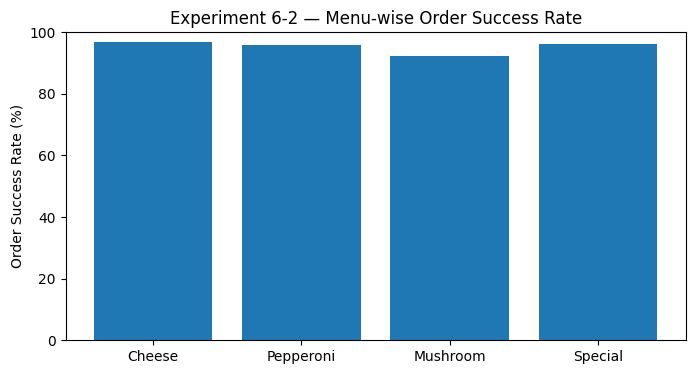

In [ ]:
# 10. Menu-wise Order Success Analysis
MENU_NAMES = {1: 'Cheese', 2: 'Pepperoni', 3: 'Mushroom', 4: 'Special'}
EVAL_EPISODES = 100
EVAL_SEED = 42

# 기존 model을 초기화하거나 학습하지 않고, 저장된 최종 가중치를 별도 모델에 불러옴
eval_model = ActorCritic().to(device)
eval_path = CHECKPOINT_DIR / 'actor_critic_exp6_2_seed123_ep4000.pth'
eval_model.load_state_dict(torch.load(eval_path, map_location=device, weights_only=True))
eval_model.eval()

torch.manual_seed(EVAL_SEED)  # 평가 행동 샘플링 재현성

menu_stats = {menu: {'orders': 0, 'success': 0, 'timeout': 0} for menu in MENU_NAMES}
eval_env = PizzaShopEnv()

for ep in range(EVAL_EPISODES):
    state, _ = eval_env.reset(seed=EVAL_SEED if ep == 0 else None)
    for order in eval_env.orders:
        menu_stats[order['menu']]['orders'] += 1

    done = False
    while not done:
        before_orders = [order.copy() for order in eval_env.orders]
        with torch.no_grad():
            probs = eval_model.pi(torch.as_tensor(state, dtype=torch.float32, device=device))
            action = int(Categorical(probs=probs).sample().item())

        next_state, reward, terminated, truncated, info = eval_env.step(action)

        # 성공한 서빙은 FIFO 첫 주문에 해당함
        if info['success_count']:
            menu_stats[before_orders[0]['menu']]['success'] += 1

        # 성공한 주문을 제외하고 타이머가 0이 된 주문을 메뉴별로 집계함
        remaining_before_timeout = before_orders[info['success_count']:]
        for order in remaining_before_timeout:
            if order['timer'] - 1 <= 0:
                menu_stats[order['menu']]['timeout'] += 1

        state = next_state
        done = terminated or truncated

print(f'=== Menu-wise Order Success Rate ({EVAL_EPISODES} Evaluation Episodes, Seed {EVAL_SEED}) ===')
print(f'{"Menu":<12} {"Orders":>8} {"Success":>9} {"Timeout":>9} {"Success Rate":>14}')
for menu, name in MENU_NAMES.items():
    result = menu_stats[menu]
    rate = 100 * result['success'] / result['orders'] if result['orders'] else 0
    print(f'{name:<12} {result["orders"]:>8} {result["success"]:>9} {result["timeout"]:>9} {rate:>13.2f}%')

all_orders = sum(x['orders'] for x in menu_stats.values())
all_success = sum(x['success'] for x in menu_stats.values())
print(f'Total: {all_success}/{all_orders} ({100 * all_success / all_orders:.2f}%)')

plt.figure(figsize=(8, 4))
plt.bar([MENU_NAMES[m] for m in MENU_NAMES],
        [100 * menu_stats[m]['success'] / menu_stats[m]['orders'] if menu_stats[m]['orders'] else 0 for m in MENU_NAMES])
plt.ylabel('Order Success Rate (%)')
plt.ylim(0, 100)
plt.title('Experiment 6-2 — Menu-wise Order Success Rate')
plt.show()

#### **실험 6-2 결과 분석 (Seed 123)**

마지막 100에피소드에서 주문 처리 성공률 96.50%, 평균 보상 633.85를 기록하여 기존 실험 6-1과 유사한 학습 성능을 보임.

동일한 평가 시드(42)를 적용한 별도 평가에서는 전체 주문 처리 성공률 95.25%, 스페셜 피자 성공률 96.23%를 기록하였으며, 모든 메뉴에서 90% 이상의 성공률을 달성함.

또한 Idle 행동 비율은 3.92%, Olive 추가 행동 비율은 6.64%로 기존 실험 6-1과 유사한 행동 분포를 보임.

####
## 3-4. 실험 6-3 (Seed 2026)

Device: cpu
Checkpoint saved: episode 0 -> actor_critic_exp6_3_seed2026_checkpoints/actor_critic_exp6_3_seed2026_ep0.pth
Episode   50 | Avg Reward (50):  -283.94 | Success: 0 | Timeout: 4
Episode  100 | Avg Reward (50):  -265.34 | Success: 1 | Timeout: 3
Episode  150 | Avg Reward (50):  -228.48 | Success: 0 | Timeout: 4
Episode  200 | Avg Reward (50):  -243.71 | Success: 0 | Timeout: 4
Episode  250 | Avg Reward (50):  -185.10 | Success: 0 | Timeout: 4
Episode  300 | Avg Reward (50):  -194.96 | Success: 2 | Timeout: 2
Episode  350 | Avg Reward (50):  -162.09 | Success: 0 | Timeout: 4
Episode  400 | Avg Reward (50):  -167.05 | Success: 0 | Timeout: 4
Episode  450 | Avg Reward (50):  -164.60 | Success: 1 | Timeout: 3
Episode  500 | Avg Reward (50):  -109.13 | Success: 2 | Timeout: 2
Checkpoint saved: episode 500 -> actor_critic_exp6_3_seed2026_checkpoints/actor_critic_exp6_3_seed2026_ep500.pth
Episode  550 | Avg Reward (50):  -133.67 | Success: 0 | Timeout: 4
Episode  600 | Avg Reward (50

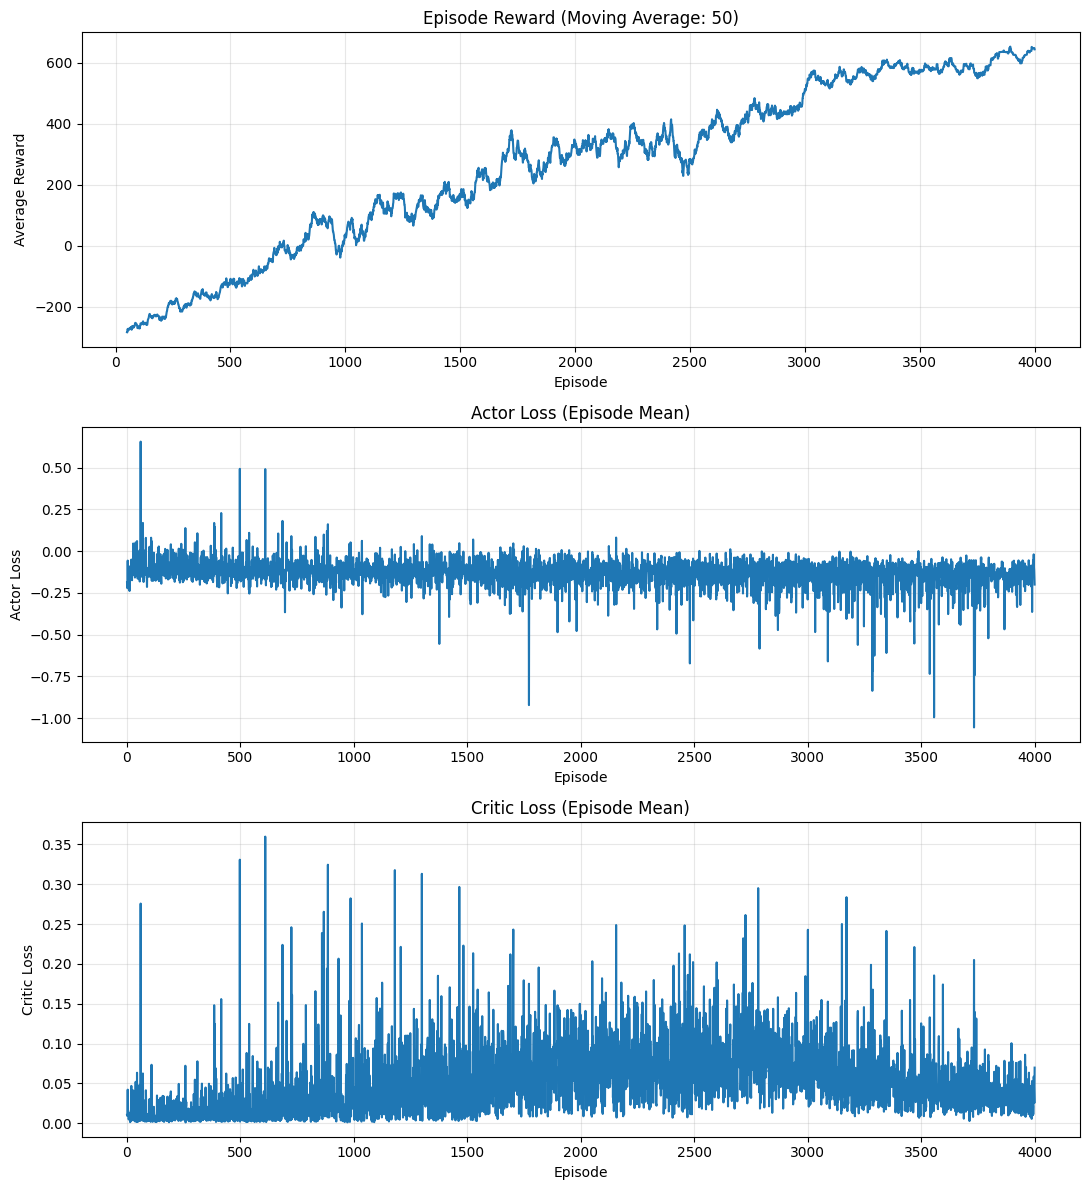

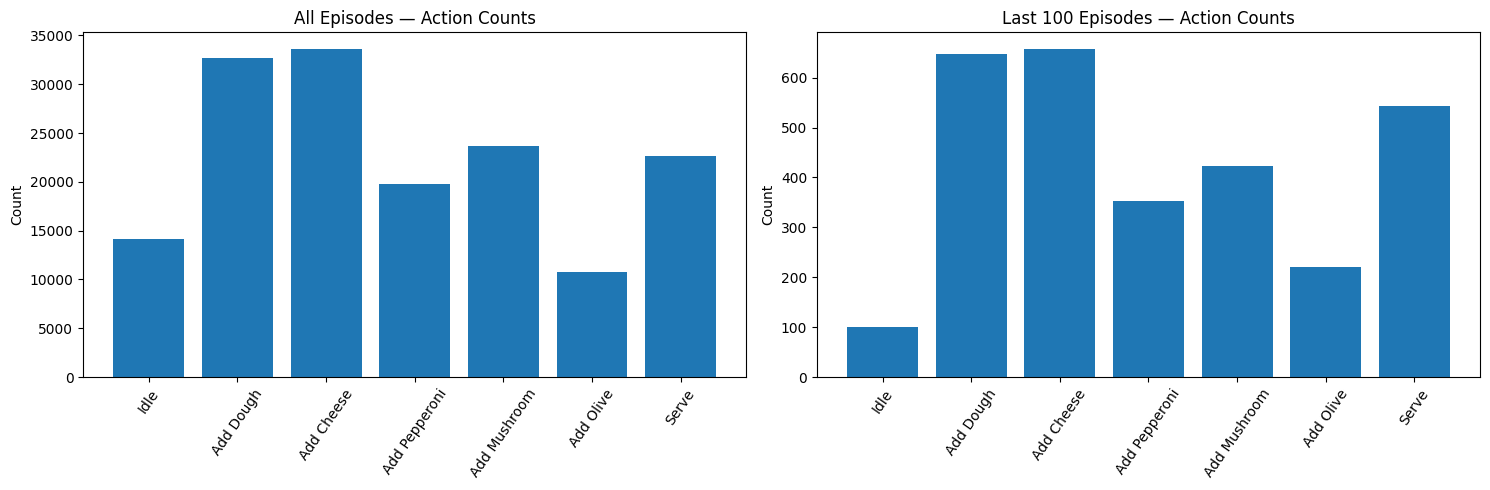

=== Last 100 Episodes Action Distribution ===
Idle            :   3.40%
Add Dough       :  21.98%
Add Cheese      :  22.35%
Add Pepperoni   :  11.96%
Add Mushroom    :  14.40%
Add Olive       :   7.47%
Serve           :  18.44%


In [ ]:
# 1. Imports & Hyperparameters
import random
import shutil
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym
from gymnasium import spaces
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.distributions import Categorical

SEED = 2026
NUM_EPISODES = 4000 # ⭐ 학습 에피소드 2000 → 4000으로 증가
LEARNING_RATE = 0.0002
GAMMA = 0.98
N_ROLLOUT = 10
REWARD_SCALE = 100.0
ENTROPY_COEF = 0.05 # ⭐ 엔트로피 보너스 계수 0.01 → 0.05로 증가
SHAPING_REWARD = 5.0 # ⭐ 올바른 재료 추가 시 +5
COMPLETION_SHAPING_REWARD = 10.0 # ⭐ 주문에 필요한 마지막 재료를 추가하여 피자를 완성하면 +10

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

# 2. Pizza Shop Environment
class PizzaShopEnv(gym.Env):
    def __init__(self):
        super().__init__()
        self.max_orders = 4
        self.max_steps = 100
        self.menus = {
            1: [1, 1, 0, 0, 0],  # Cheese
            2: [1, 1, 1, 0, 0],  # Pepperoni
            3: [1, 1, 0, 1, 0],  # Mushroom
            4: [1, 1, 1, 1, 1],  # Special
        }
        # 0 Idle, 1 Dough, 2 Cheese, 3 Pepperoni, 4 Mushroom, 5 Olive, 6 Serve
        self.action_space = spaces.Discrete(7)
        self.observation_space = spaces.Box(
            low=np.zeros(13, dtype=np.float32),
            high=np.array([1, 1, 1, 1, 1, 4, 1, 4, 1, 4, 1, 4, 1], dtype=np.float32),
            dtype=np.float32,
        )
        self.counter = np.zeros(5, dtype=np.float32)
        self.orders = []
        self.steps = 0

    def _get_obs(self):
        obs = list(self.counter)
        for i in range(self.max_orders):
            if i < len(self.orders):
                obs.extend([self.orders[i]['menu'], self.orders[i]['timer'] / 48.0])
            else:
                obs.extend([0, 0])
        return np.array(obs, dtype=np.float32)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.counter = np.zeros(5, dtype=np.float32)
        self.orders = [
            {'menu': int(self.np_random.choice([1, 2, 3, 4])),
             'timer': int(self.np_random.integers(36, 49))}
            for _ in range(self.max_orders)
        ]
        self.steps = 0
        return self._get_obs(), {}

    def _next_required_ingredient(self):
        if not self.orders:
            return None
        expected = self.menus[self.orders[0]['menu']]
        for idx, needed in enumerate(expected):
            if needed == 1 and self.counter[idx] == 0:
                return idx
        return None

    def step(self, action):
        action = int(action)
        reward = -0.1
        success_count = 0
        timeout_count = 0
        self.steps += 1
        next_required = self._next_required_ingredient()

        if action == 0:
            pass
        elif action == 1:  # Dough
            if self.counter[0] == 0:
                self.counter[0] = 1
                if next_required == 0:
                    reward += (COMPLETION_SHAPING_REWARD
                               if np.array_equal(self.counter, self.menus[self.orders[0]['menu']])
                               else SHAPING_REWARD)
            else:
                reward -= 2
        elif action == 2:  # Cheese
            if self.counter[0] == 1 and self.counter[1] == 0:
                self.counter[1] = 1
                if next_required == 1:
                    reward += (COMPLETION_SHAPING_REWARD
                               if np.array_equal(self.counter, self.menus[self.orders[0]['menu']])
                               else SHAPING_REWARD)
            else:
                reward -= 2
        elif action in (3, 4, 5):  # Toppings
            idx = action - 1
            if self.counter[0] == 1 and self.counter[1] == 1 and self.counter[idx] == 0:
                self.counter[idx] = 1
                if next_required == idx:
                    reward += (COMPLETION_SHAPING_REWARD
                               if np.array_equal(self.counter, self.menus[self.orders[0]['menu']])
                               else SHAPING_REWARD)
            else:
                reward -= 2
        elif action == 6:  # Serve (FIFO)
            if self.orders:
                expected = self.menus[self.orders[0]['menu']]
                if np.array_equal(self.counter, expected):
                    reward += 150
                    success_count += 1
                    self.orders.pop(0)
                else:
                    reward -= 15
                self.counter = np.zeros(5, dtype=np.float32)

        # Every active order loses one step, including on a serve action.
        for order in self.orders:
            order['timer'] -= 1
        remaining = []
        for order in self.orders:
            if order['timer'] <= 0:
                reward -= 50
                timeout_count += 1
            else:
                remaining.append(order)
        self.orders = remaining

        terminated = len(self.orders) == 0
        truncated = self.steps >= self.max_steps and not terminated
        info = {'success_count': success_count, 'timeout_count': timeout_count}
        return self._get_obs(), reward, terminated, truncated, info

# 3. Shared-Network Actor-Critic
class ActorCritic(nn.Module):
    def __init__(self, state_dim=13, action_dim=7):
        super().__init__()
        self.data = []
        self.fc1 = nn.Linear(state_dim, 256)
        self.fc_pi = nn.Linear(256, action_dim)
        self.fc_v = nn.Linear(256, 1)
        self.optimizer = optim.Adam(self.parameters(), lr=LEARNING_RATE)

    def pi(self, x, softmax_dim=-1):
        x = F.relu(self.fc1(x))
        return F.softmax(self.fc_pi(x), dim=softmax_dim)

    def v(self, x):
        x = F.relu(self.fc1(x))
        return self.fc_v(x)

    def put_data(self, transition):
        self.data.append(transition)

    def make_batch(self):
        s_lst, a_lst, r_lst, s_prime_lst, terminal_lst = [], [], [], [], []
        for s, a, r, s_prime, terminated in self.data:
            s_lst.append(s)
            a_lst.append([a])
            r_lst.append([r / REWARD_SCALE])
            s_prime_lst.append(s_prime)
            terminal_lst.append([0.0 if terminated else 1.0])
        self.data = []
        s = torch.as_tensor(np.asarray(s_lst), dtype=torch.float32, device=device)
        a = torch.as_tensor(a_lst, dtype=torch.long, device=device)
        r = torch.as_tensor(r_lst, dtype=torch.float32, device=device)
        s_prime = torch.as_tensor(np.asarray(s_prime_lst), dtype=torch.float32, device=device)
        mask = torch.as_tensor(terminal_lst, dtype=torch.float32, device=device)
        return s, a, r, s_prime, mask

    def train_net(self):
        if not self.data:
            return None, None
        s, a, r, s_prime, mask = self.make_batch()
        # 10개 전이를 모아도 TD target은 각 전이에 대한 1-step target임
        with torch.no_grad():
            td_target = r + GAMMA * self.v(s_prime) * mask
        value = self.v(s)
        delta = td_target - value
        pi = self.pi(s, softmax_dim=1)
        pi_a = pi.gather(1, a).clamp_min(1e-8)
        entropy = Categorical(probs=pi).entropy().mean()
        actor_loss = (-torch.log(pi_a) * delta.detach()).mean() - ENTROPY_COEF * entropy
        critic_loss = F.smooth_l1_loss(value, td_target)
        loss = actor_loss + critic_loss

        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()
        return actor_loss.mean().item(), critic_loss.item()

# 4. Initialize & Checkpoint Setup
env = PizzaShopEnv()
env.reset(seed=SEED)
model = ActorCritic().to(device)
CHECKPOINT_DIR = Path('actor_critic_exp6_3_seed2026_checkpoints')
CHECKPOINT_DIR.mkdir(exist_ok=True)

def save_checkpoint(episode):
    path = CHECKPOINT_DIR / f'actor_critic_exp6_3_seed2026_ep{episode}.pth'
    torch.save(model.state_dict(), path)
    print(f'Checkpoint saved: episode {episode} -> {path}')

save_checkpoint(0)

# 5. Training — 10-transition mini-batches, 1-step TD
# Gymnasium: terminated는 진짜 종료, truncated는 시간 제한 종료.
# truncated에서는 에피소드를 멈추되 TD target의 다음 상태 가치는 bootstrap 가능하도록 유지.
episode_rewards, episode_successes, episode_timeouts = [], [], []
episode_actor_losses, episode_critic_losses = [], []
action_counts = np.zeros(7, dtype=np.int64)
all_episode_actions = []

for episode in range(1, NUM_EPISODES + 1):
    state, _ = env.reset()
    done = False
    total_reward, successes, timeouts = 0.0, 0, 0
    actor_losses, critic_losses, actions_this_episode = [], [], []

    while not done:
        for t in range(N_ROLLOUT):
            with torch.no_grad():
                state_tensor = torch.as_tensor(state, dtype=torch.float32, device=device)
                probs = model.pi(state_tensor)
                action = int(Categorical(probs).sample().item())

            next_state, reward, terminated, truncated, info = env.step(action)
            model.put_data((state, action, reward, next_state, terminated))
            action_counts[action] += 1
            actions_this_episode.append(action)
            total_reward += reward  # 보고용 점수는 원래 보상 단위로 기록
            successes += info['success_count']
            timeouts += info['timeout_count']
            state = next_state
            done = terminated or truncated
            if done:
                break

        actor_loss, critic_loss = model.train_net()
        if actor_loss is not None:
            actor_losses.append(actor_loss)
            critic_losses.append(critic_loss)

    episode_rewards.append(total_reward)
    episode_successes.append(successes)
    episode_timeouts.append(timeouts)
    episode_actor_losses.append(float(np.mean(actor_losses)))
    episode_critic_losses.append(float(np.mean(critic_losses)))
    all_episode_actions.append(actions_this_episode)

    if episode % 50 == 0:
        print(f'Episode {episode:4d} | Avg Reward (50): {np.mean(episode_rewards[-50:]):8.2f} '
              f'| Success: {successes} | Timeout: {timeouts}')
    if episode in (500, 1000, 2000, 3000, 4000):
        save_checkpoint(episode)

last_100_action_counts = np.zeros(7, dtype=np.int64)
for actions in all_episode_actions[-100:]:
    for a in actions:
        last_100_action_counts[a] += 1

# 6. Results
last_100_success = sum(episode_successes[-100:])
last_100_timeout = sum(episode_timeouts[-100:])
last_100_orders = last_100_success + last_100_timeout
total_success = sum(episode_successes)
total_timeout = sum(episode_timeouts)
total_orders = total_success + total_timeout

print('=== Actor-Critic Experiment 6-3 (Seed 2026, Entropy 0.05, 4000 Episodes, Reward Shaping +5 / Completion +10) ===')
print(f'Last 100 Episodes Average Reward: {np.mean(episode_rewards[-100:]):.2f}')
print(f'Last 50 Episodes Average Reward: {np.mean(episode_rewards[-50:]):.2f}')
print(f'Overall Success: {total_success}/{total_orders} ({100*total_success/total_orders if total_orders else 0:.2f}%)')
print(f'Overall Timeout: {total_timeout}/{total_orders} ({100*total_timeout/total_orders if total_orders else 0:.2f}%)')
print(f'Last 100 Episodes Order Success Rate: {last_100_success}/{last_100_orders} ({100*last_100_success/last_100_orders if last_100_orders else 0:.2f}%)')
print(f'Last 100 Episodes Average Actor Loss: {np.mean(episode_actor_losses[-100:]):.4f}')
print(f'Last 100 Episodes Average Critic Loss: {np.mean(episode_critic_losses[-100:]):.4f}')

# 7. Learning Curves
def moving_average(values, window=50):
    return np.convolve(np.asarray(values, dtype=np.float64), np.ones(window) / window, mode='valid')

fig, axes = plt.subplots(3, 1, figsize=(11, 12))
axes[0].plot(np.arange(50, NUM_EPISODES + 1), moving_average(episode_rewards, 50))
axes[0].set_title('Episode Reward (Moving Average: 50)')
axes[0].set_xlabel('Episode')
axes[0].set_ylabel('Average Reward')
axes[1].plot(range(1, NUM_EPISODES + 1), episode_actor_losses)
axes[1].set_title('Actor Loss (Episode Mean)')
axes[1].set_xlabel('Episode')
axes[1].set_ylabel('Actor Loss')
axes[2].plot(range(1, NUM_EPISODES + 1), episode_critic_losses)
axes[2].set_title('Critic Loss (Episode Mean)')
axes[2].set_xlabel('Episode')
axes[2].set_ylabel('Critic Loss')
for ax in axes: ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 8. Action Distribution
names = ['Idle', 'Add Dough', 'Add Cheese', 'Add Pepperoni',
         'Add Mushroom', 'Add Olive', 'Serve']
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].bar(names, action_counts)
axes[0].set_title('All Episodes — Action Counts')
axes[0].set_ylabel('Count')
axes[1].bar(names, last_100_action_counts)
axes[1].set_title('Last 100 Episodes — Action Counts')
axes[1].set_ylabel('Count')
for ax in axes: ax.tick_params(axis='x', rotation=55)
plt.tight_layout()
plt.show()

last_total = last_100_action_counts.sum()
print('=== Last 100 Episodes Action Distribution ===')
for name, count in zip(names, last_100_action_counts):
    print(f'{name:16s}: {100*count/last_total if last_total else 0:6.2f}%')

### 추가 분석: 메뉴별 주문 처리 성공률

- 학습된 모델을 이용해 100개 에피소드 평가
- 치즈, 페퍼로니, 버섯, 스페셜 메뉴별 주문 수 및 성공 건수 확인
- 메뉴별 주문 처리 성공률을 비교하여 실패가 집중되는 메뉴 분석

=== Menu-wise Order Success Rate (100 Evaluation Episodes, Seed 42) ===
Menu           Orders   Success   Timeout   Success Rate
Cheese             93        91         2         97.85%
Pepperoni          99        91         8         91.92%
Mushroom          102        95         7         93.14%
Special           106       100         6         94.34%
Total: 377/400 (94.25%)


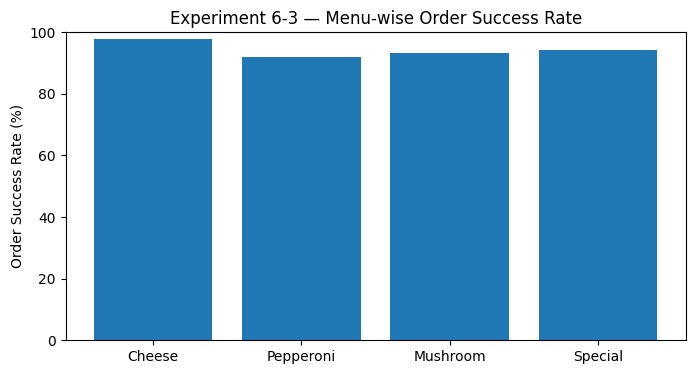

In [ ]:
# 10. Menu-wise Order Success Analysis
MENU_NAMES = {1: 'Cheese', 2: 'Pepperoni', 3: 'Mushroom', 4: 'Special'}
EVAL_EPISODES = 100
EVAL_SEED = 42

# 기존 model을 초기화하거나 학습하지 않고, 저장된 최종 가중치를 별도 모델에 불러옴
eval_model = ActorCritic().to(device)
eval_path = CHECKPOINT_DIR / 'actor_critic_exp6_3_seed2026_ep4000.pth'
eval_model.load_state_dict(torch.load(eval_path, map_location=device, weights_only=True))
eval_model.eval()

torch.manual_seed(EVAL_SEED)  # 평가 행동 샘플링 재현성

menu_stats = {menu: {'orders': 0, 'success': 0, 'timeout': 0} for menu in MENU_NAMES}
eval_env = PizzaShopEnv()

for ep in range(EVAL_EPISODES):
    state, _ = eval_env.reset(seed=EVAL_SEED if ep == 0 else None)
    for order in eval_env.orders:
        menu_stats[order['menu']]['orders'] += 1

    done = False
    while not done:
        before_orders = [order.copy() for order in eval_env.orders]
        with torch.no_grad():
            probs = eval_model.pi(torch.as_tensor(state, dtype=torch.float32, device=device))
            action = int(Categorical(probs=probs).sample().item())

        next_state, reward, terminated, truncated, info = eval_env.step(action)

        # 성공한 서빙은 FIFO 첫 주문에 해당함
        if info['success_count']:
            menu_stats[before_orders[0]['menu']]['success'] += 1

        # 성공한 주문을 제외하고 타이머가 0이 된 주문을 메뉴별로 집계함
        remaining_before_timeout = before_orders[info['success_count']:]
        for order in remaining_before_timeout:
            if order['timer'] - 1 <= 0:
                menu_stats[order['menu']]['timeout'] += 1

        state = next_state
        done = terminated or truncated

print(f'=== Menu-wise Order Success Rate ({EVAL_EPISODES} Evaluation Episodes, Seed {EVAL_SEED}) ===')
print(f'{"Menu":<12} {"Orders":>8} {"Success":>9} {"Timeout":>9} {"Success Rate":>14}')
for menu, name in MENU_NAMES.items():
    result = menu_stats[menu]
    rate = 100 * result['success'] / result['orders'] if result['orders'] else 0
    print(f'{name:<12} {result["orders"]:>8} {result["success"]:>9} {result["timeout"]:>9} {rate:>13.2f}%')

all_orders = sum(x['orders'] for x in menu_stats.values())
all_success = sum(x['success'] for x in menu_stats.values())
print(f'Total: {all_success}/{all_orders} ({100 * all_success / all_orders:.2f}%)')

plt.figure(figsize=(8, 4))
plt.bar([MENU_NAMES[m] for m in MENU_NAMES],
        [100 * menu_stats[m]['success'] / menu_stats[m]['orders'] if menu_stats[m]['orders'] else 0 for m in MENU_NAMES])
plt.ylabel('Order Success Rate (%)')
plt.ylim(0, 100)
plt.title('Experiment 6-3 — Menu-wise Order Success Rate')
plt.show()

#### **실험 6-3 결과 분석 (Seed 2026)**

마지막 100에피소드에서 주문 처리 성공률 96.00%, 평균 보상 629.66을 기록하여 기존 실험 6-1 및 6-2와 유사한 학습 성능을 보임.

동일한 평가 시드(42)를 적용한 별도 평가에서는 전체 주문 처리 성공률 94.25%, 스페셜 피자 성공률 94.34%를 기록하였으며, 모든 메뉴에서 90% 이상의 성공률을 달성함.

또한 Idle 행동 비율은 3.40%, Olive 추가 행동 비율은 7.47%로 기존 실험과 유사한 행동 분포를 보임.

####
## **04. 엔트로피 보너스 계수 0.01 검증 실험**

기존 Actor-Critic 추가 test의 설정을 기반으로, 엔트로피 보너스 계수 0.01에서의 학습 성능이 다른 랜덤 시드에서도 유사하게 나타나는지 검증하고자 함.

엔트로피 보너스 계수 0.01, Reward Shaping(+5, +10), 학습 횟수 4,000에피소드를 포함한 기존 실험 환경 및 하이퍼파라미터를 동일하게 유지하고, 학습 시드만 변경하여 추가 실험을 진행함.

### 4-1. 실험 조건

| 실험 번호 | 학습 시드 | 평가 시드 | 엔트로피 계수 | 학습 에피소드 수 | 비고 |
|---|---:|---:|---:|---:|---|
| 추가 test-1 | 42 | 42 | 0.01 | 4,000 | 기존 실험 결과 활용 |
| 추가 test-2 | 123 | 42 | 0.01 | 4,000 | 추가 검증 |
| 추가 test-3 | 2026 | 42 | 0.01 | 4,000 | 추가 검증 |

학습 시드에 따른 성능 차이를 확인하기 위해 학습 시드만 변경하고, 평가 시드는 42로 고정하여 동일한 평가 조건에서 성능을 비교함.

### 4-2. 추가 test-1 (Seed 42)

기존 Actor-Critic 추가 test의 학습 및 평가 결과를 활용함.

| 평가 지표 | 결과 |
|---|---:|
| 마지막 100에피소드 주문 성공률 | 59.25% |
| 마지막 100에피소드 평균 보상 | 287.05 |
| 별도 평가 전체 성공률 | 48.50% |
| 치즈 피자 성공률 | 62.37% |
| 페퍼로니 피자 성공률 | 60.61% |
| 버섯 피자 성공률 | 74.51% |
| 스페셜 피자 성공률 | 0.00% |

### 4-3. 추가 test-2 (Seed 123)

기존 추가 test의 환경 및 하이퍼파라미터를 동일하게 유지하고, 학습 시드를 123으로 변경하여 모델을 초기화한 후 처음부터 학습을 진행함.

### 4-4. 추가 test-3 (Seed 2026)

기존 추가 test의 환경 및 하이퍼파라미터를 동일하게 유지하고, 학습 시드를 2026으로 변경하여 모델을 초기화한 후 처음부터 학습을 진행함.

####
## 4-2. 추가 test-1 (Seed 42)

Device: cpu
Checkpoint saved: episode 0 -> actor_critic_test_seed42_checkpoints/actor_critic_test_seed42_ep0.pth
Episode   50 | Avg Reward (50):  -274.78 | Success: 0 | Timeout: 4
Episode  100 | Avg Reward (50):  -260.26 | Success: 0 | Timeout: 4
Episode  150 | Avg Reward (50):  -250.96 | Success: 0 | Timeout: 4
Episode  200 | Avg Reward (50):  -234.12 | Success: 0 | Timeout: 4
Episode  250 | Avg Reward (50):  -239.60 | Success: 0 | Timeout: 4
Episode  300 | Avg Reward (50):  -240.16 | Success: 0 | Timeout: 4
Episode  350 | Avg Reward (50):  -223.02 | Success: 0 | Timeout: 4
Episode  400 | Avg Reward (50):  -227.89 | Success: 0 | Timeout: 4
Episode  450 | Avg Reward (50):  -237.66 | Success: 0 | Timeout: 4
Episode  500 | Avg Reward (50):  -207.82 | Success: 0 | Timeout: 4
Checkpoint saved: episode 500 -> actor_critic_test_seed42_checkpoints/actor_critic_test_seed42_ep500.pth
Episode  550 | Avg Reward (50):  -199.10 | Success: 0 | Timeout: 4
Episode  600 | Avg Reward (50):  -183.93 | Su

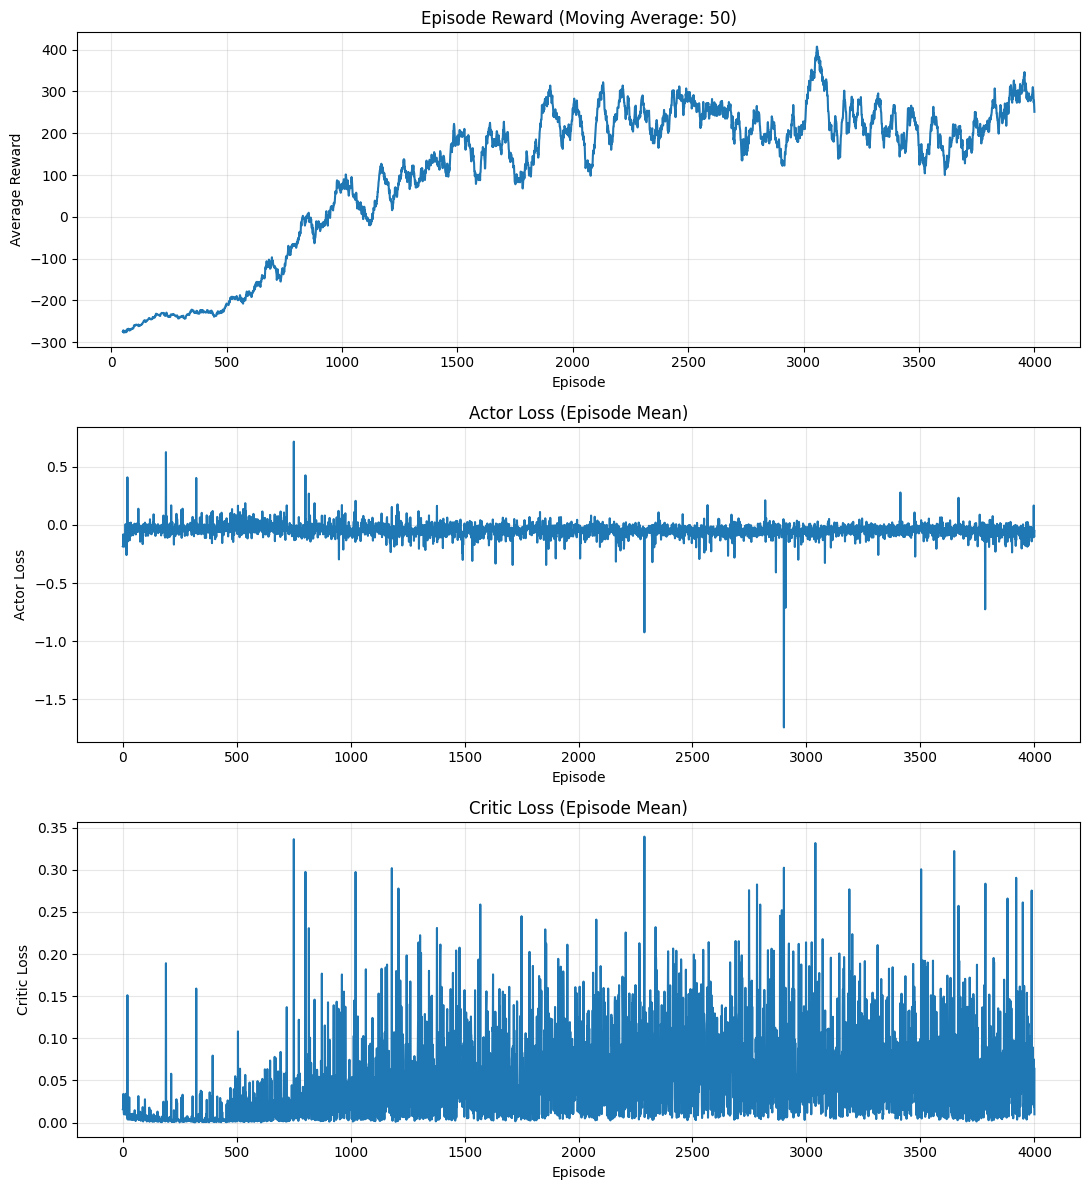

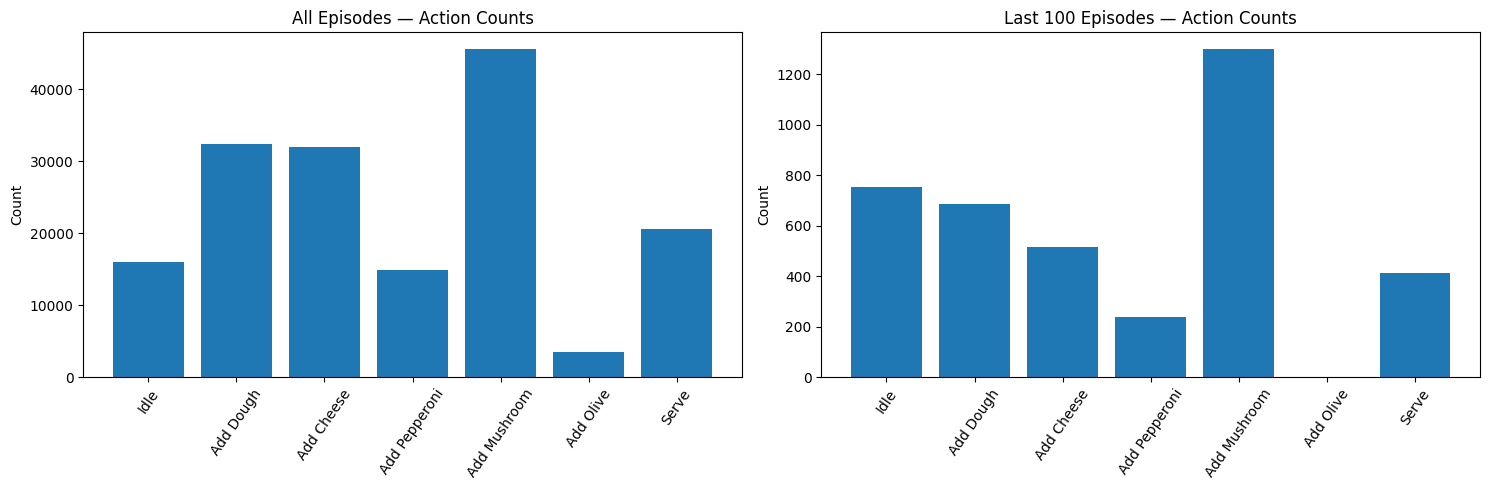

=== Last 100 Episodes Action Distribution ===
Idle            :  19.31%
Add Dough       :  17.52%
Add Cheese      :  13.16%
Add Pepperoni   :   6.09%
Add Mushroom    :  33.32%
Add Olive       :   0.03%
Serve           :  10.58%


In [ ]:
# 1. Imports & Hyperparameters
import random
import shutil
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym
from gymnasium import spaces
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.distributions import Categorical

SEED = 42
NUM_EPISODES = 4000
LEARNING_RATE = 0.0002
GAMMA = 0.98
N_ROLLOUT = 10
REWARD_SCALE = 100.0
ENTROPY_COEF = 0.01
SHAPING_REWARD = 5.0 # ⭐ 올바른 재료 추가 시 +5
COMPLETION_SHAPING_REWARD = 10.0 # ⭐ 주문에 필요한 마지막 재료를 추가하여 피자를 완성하면 +10

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

# 2. Pizza Shop Environment
class PizzaShopEnv(gym.Env):
    def __init__(self):
        super().__init__()
        self.max_orders = 4
        self.max_steps = 100
        self.menus = {
            1: [1, 1, 0, 0, 0],  # Cheese
            2: [1, 1, 1, 0, 0],  # Pepperoni
            3: [1, 1, 0, 1, 0],  # Mushroom
            4: [1, 1, 1, 1, 1],  # Special
        }
        # 0 Idle, 1 Dough, 2 Cheese, 3 Pepperoni, 4 Mushroom, 5 Olive, 6 Serve
        self.action_space = spaces.Discrete(7)
        self.observation_space = spaces.Box(
            low=np.zeros(13, dtype=np.float32),
            high=np.array([1, 1, 1, 1, 1, 4, 1, 4, 1, 4, 1, 4, 1], dtype=np.float32),
            dtype=np.float32,
        )
        self.counter = np.zeros(5, dtype=np.float32)
        self.orders = []
        self.steps = 0

    def _get_obs(self):
        obs = list(self.counter)
        for i in range(self.max_orders):
            if i < len(self.orders):
                obs.extend([self.orders[i]['menu'], self.orders[i]['timer'] / 48.0])
            else:
                obs.extend([0, 0])
        return np.array(obs, dtype=np.float32)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.counter = np.zeros(5, dtype=np.float32)
        self.orders = [
            {'menu': int(self.np_random.choice([1, 2, 3, 4])),
             'timer': int(self.np_random.integers(36, 49))}
            for _ in range(self.max_orders)
        ]
        self.steps = 0
        return self._get_obs(), {}

    def _next_required_ingredient(self):
        if not self.orders:
            return None
        expected = self.menus[self.orders[0]['menu']]
        for idx, needed in enumerate(expected):
            if needed == 1 and self.counter[idx] == 0:
                return idx
        return None

    def step(self, action):
        action = int(action)
        reward = -0.1
        success_count = 0
        timeout_count = 0
        self.steps += 1
        next_required = self._next_required_ingredient()

        if action == 0:
            pass
        elif action == 1:  # Dough
            if self.counter[0] == 0:
                self.counter[0] = 1
                if next_required == 0:
                    reward += (COMPLETION_SHAPING_REWARD
                               if np.array_equal(self.counter, self.menus[self.orders[0]['menu']])
                               else SHAPING_REWARD)
            else:
                reward -= 2
        elif action == 2:  # Cheese
            if self.counter[0] == 1 and self.counter[1] == 0:
                self.counter[1] = 1
                if next_required == 1:
                    reward += (COMPLETION_SHAPING_REWARD
                               if np.array_equal(self.counter, self.menus[self.orders[0]['menu']])
                               else SHAPING_REWARD)
            else:
                reward -= 2
        elif action in (3, 4, 5):  # Toppings
            idx = action - 1
            if self.counter[0] == 1 and self.counter[1] == 1 and self.counter[idx] == 0:
                self.counter[idx] = 1
                if next_required == idx:
                    reward += (COMPLETION_SHAPING_REWARD
                               if np.array_equal(self.counter, self.menus[self.orders[0]['menu']])
                               else SHAPING_REWARD)
            else:
                reward -= 2
        elif action == 6:  # Serve (FIFO)
            if self.orders:
                expected = self.menus[self.orders[0]['menu']]
                if np.array_equal(self.counter, expected):
                    reward += 150
                    success_count += 1
                    self.orders.pop(0)
                else:
                    reward -= 15
                self.counter = np.zeros(5, dtype=np.float32)

        # Every active order loses one step, including on a serve action.
        for order in self.orders:
            order['timer'] -= 1
        remaining = []
        for order in self.orders:
            if order['timer'] <= 0:
                reward -= 50
                timeout_count += 1
            else:
                remaining.append(order)
        self.orders = remaining

        terminated = len(self.orders) == 0
        truncated = self.steps >= self.max_steps and not terminated
        info = {'success_count': success_count, 'timeout_count': timeout_count}
        return self._get_obs(), reward, terminated, truncated, info

# 3. Shared-Network Actor-Critic
class ActorCritic(nn.Module):
    def __init__(self, state_dim=13, action_dim=7):
        super().__init__()
        self.data = []
        self.fc1 = nn.Linear(state_dim, 256)
        self.fc_pi = nn.Linear(256, action_dim)
        self.fc_v = nn.Linear(256, 1)
        self.optimizer = optim.Adam(self.parameters(), lr=LEARNING_RATE)

    def pi(self, x, softmax_dim=-1):
        x = F.relu(self.fc1(x))
        return F.softmax(self.fc_pi(x), dim=softmax_dim)

    def v(self, x):
        x = F.relu(self.fc1(x))
        return self.fc_v(x)

    def put_data(self, transition):
        self.data.append(transition)

    def make_batch(self):
        s_lst, a_lst, r_lst, s_prime_lst, terminal_lst = [], [], [], [], []
        for s, a, r, s_prime, terminated in self.data:
            s_lst.append(s)
            a_lst.append([a])
            r_lst.append([r / REWARD_SCALE])
            s_prime_lst.append(s_prime)
            terminal_lst.append([0.0 if terminated else 1.0])
        self.data = []
        s = torch.as_tensor(np.asarray(s_lst), dtype=torch.float32, device=device)
        a = torch.as_tensor(a_lst, dtype=torch.long, device=device)
        r = torch.as_tensor(r_lst, dtype=torch.float32, device=device)
        s_prime = torch.as_tensor(np.asarray(s_prime_lst), dtype=torch.float32, device=device)
        mask = torch.as_tensor(terminal_lst, dtype=torch.float32, device=device)
        return s, a, r, s_prime, mask

    def train_net(self):
        if not self.data:
            return None, None
        s, a, r, s_prime, mask = self.make_batch()
        # 10개 전이를 모아도 TD target은 각 전이에 대한 1-step target임
        with torch.no_grad():
            td_target = r + GAMMA * self.v(s_prime) * mask
        value = self.v(s)
        delta = td_target - value
        pi = self.pi(s, softmax_dim=1)
        pi_a = pi.gather(1, a).clamp_min(1e-8)
        entropy = Categorical(probs=pi).entropy().mean()
        actor_loss = (-torch.log(pi_a) * delta.detach()).mean() - ENTROPY_COEF * entropy
        critic_loss = F.smooth_l1_loss(value, td_target)
        loss = actor_loss + critic_loss

        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()
        return actor_loss.mean().item(), critic_loss.item()

# 4. Initialize & Checkpoint Setup
env = PizzaShopEnv()
env.reset(seed=SEED)
model = ActorCritic().to(device)
CHECKPOINT_DIR = Path('actor_critic_test_seed42_checkpoints')
CHECKPOINT_DIR.mkdir(exist_ok=True)

def save_checkpoint(episode):
    path = CHECKPOINT_DIR / f'actor_critic_test_seed42_ep{episode}.pth'
    torch.save(model.state_dict(), path)
    print(f'Checkpoint saved: episode {episode} -> {path}')

save_checkpoint(0)

# 5. Training — 10-transition mini-batches, 1-step TD
# Gymnasium: terminated는 진짜 종료, truncated는 시간 제한 종료.
# truncated에서는 에피소드를 멈추되 TD target의 다음 상태 가치는 bootstrap 가능하도록 유지.
episode_rewards, episode_successes, episode_timeouts = [], [], []
episode_actor_losses, episode_critic_losses = [], []
action_counts = np.zeros(7, dtype=np.int64)
all_episode_actions = []

for episode in range(1, NUM_EPISODES + 1):
    state, _ = env.reset()
    done = False
    total_reward, successes, timeouts = 0.0, 0, 0
    actor_losses, critic_losses, actions_this_episode = [], [], []

    while not done:
        for t in range(N_ROLLOUT):
            with torch.no_grad():
                state_tensor = torch.as_tensor(state, dtype=torch.float32, device=device)
                probs = model.pi(state_tensor)
                action = int(Categorical(probs).sample().item())

            next_state, reward, terminated, truncated, info = env.step(action)
            model.put_data((state, action, reward, next_state, terminated))
            action_counts[action] += 1
            actions_this_episode.append(action)
            total_reward += reward  # 보고용 점수는 원래 보상 단위로 기록
            successes += info['success_count']
            timeouts += info['timeout_count']
            state = next_state
            done = terminated or truncated
            if done:
                break

        actor_loss, critic_loss = model.train_net()
        if actor_loss is not None:
            actor_losses.append(actor_loss)
            critic_losses.append(critic_loss)

    episode_rewards.append(total_reward)
    episode_successes.append(successes)
    episode_timeouts.append(timeouts)
    episode_actor_losses.append(float(np.mean(actor_losses)))
    episode_critic_losses.append(float(np.mean(critic_losses)))
    all_episode_actions.append(actions_this_episode)

    if episode % 50 == 0:
        print(f'Episode {episode:4d} | Avg Reward (50): {np.mean(episode_rewards[-50:]):8.2f} '
              f'| Success: {successes} | Timeout: {timeouts}')
    if episode in (500, 1000, 2000, 3000, 4000):
        save_checkpoint(episode)

last_100_action_counts = np.zeros(7, dtype=np.int64)
for actions in all_episode_actions[-100:]:
    for a in actions:
        last_100_action_counts[a] += 1

# 6. Results
last_100_success = sum(episode_successes[-100:])
last_100_timeout = sum(episode_timeouts[-100:])
last_100_orders = last_100_success + last_100_timeout
total_success = sum(episode_successes)
total_timeout = sum(episode_timeouts)
total_orders = total_success + total_timeout

print('=== Actor-Critic Experiment test (Seed 42, Entropy 0.01, Reward Shaping +5 / Completion +10) ===')
print(f'Last 100 Episodes Average Reward: {np.mean(episode_rewards[-100:]):.2f}')
print(f'Last 50 Episodes Average Reward: {np.mean(episode_rewards[-50:]):.2f}')
print(f'Overall Success: {total_success}/{total_orders} ({100*total_success/total_orders if total_orders else 0:.2f}%)')
print(f'Overall Timeout: {total_timeout}/{total_orders} ({100*total_timeout/total_orders if total_orders else 0:.2f}%)')
print(f'Last 100 Episodes Order Success Rate: {last_100_success}/{last_100_orders} ({100*last_100_success/last_100_orders if last_100_orders else 0:.2f}%)')
print(f'Last 100 Episodes Average Actor Loss: {np.mean(episode_actor_losses[-100:]):.4f}')
print(f'Last 100 Episodes Average Critic Loss: {np.mean(episode_critic_losses[-100:]):.4f}')

# 7. Learning Curves
def moving_average(values, window=50):
    return np.convolve(np.asarray(values, dtype=np.float64), np.ones(window) / window, mode='valid')

fig, axes = plt.subplots(3, 1, figsize=(11, 12))
axes[0].plot(np.arange(50, NUM_EPISODES + 1), moving_average(episode_rewards, 50))
axes[0].set_title('Episode Reward (Moving Average: 50)')
axes[0].set_xlabel('Episode')
axes[0].set_ylabel('Average Reward')
axes[1].plot(range(1, NUM_EPISODES + 1), episode_actor_losses)
axes[1].set_title('Actor Loss (Episode Mean)')
axes[1].set_xlabel('Episode')
axes[1].set_ylabel('Actor Loss')
axes[2].plot(range(1, NUM_EPISODES + 1), episode_critic_losses)
axes[2].set_title('Critic Loss (Episode Mean)')
axes[2].set_xlabel('Episode')
axes[2].set_ylabel('Critic Loss')
for ax in axes: ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 8. Action Distribution
names = ['Idle', 'Add Dough', 'Add Cheese', 'Add Pepperoni',
         'Add Mushroom', 'Add Olive', 'Serve']
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].bar(names, action_counts)
axes[0].set_title('All Episodes — Action Counts')
axes[0].set_ylabel('Count')
axes[1].bar(names, last_100_action_counts)
axes[1].set_title('Last 100 Episodes — Action Counts')
axes[1].set_ylabel('Count')
for ax in axes: ax.tick_params(axis='x', rotation=55)
plt.tight_layout()
plt.show()

last_total = last_100_action_counts.sum()
print('=== Last 100 Episodes Action Distribution ===')
for name, count in zip(names, last_100_action_counts):
    print(f'{name:16s}: {100*count/last_total if last_total else 0:6.2f}%')


### 추가 분석: 메뉴별 주문 처리 성공률

- 학습된 모델을 이용해 100개 에피소드 평가
- 치즈, 페퍼로니, 버섯, 스페셜 메뉴별 주문 수 및 성공 건수 확인
- 메뉴별 주문 처리 성공률을 비교하여 실패가 집중되는 메뉴 분석

=== Menu-wise Order Success Rate (100 Evaluation Episodes, Seed 42) ===
Menu           Orders   Success   Timeout   Success Rate
Cheese             93        58        35         62.37%
Pepperoni          99        60        39         60.61%
Mushroom          102        76        26         74.51%
Special           106         0       106          0.00%
Total: 194/400 (48.50%)


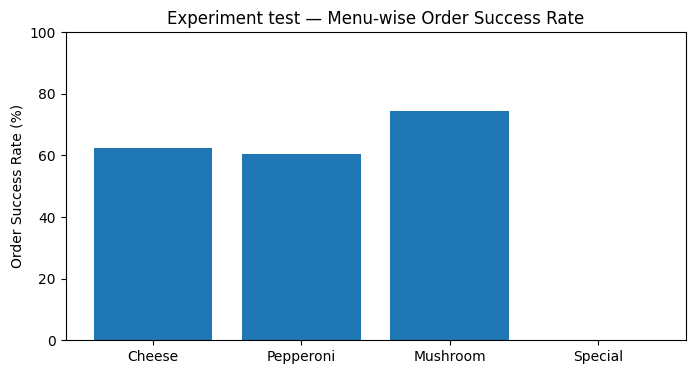

In [ ]:
# 10. Menu-wise Order Success Analysis
MENU_NAMES = {1: 'Cheese', 2: 'Pepperoni', 3: 'Mushroom', 4: 'Special'}
EVAL_EPISODES = 100

# 기존 model을 초기화하거나 학습하지 않고, 저장된 최종 가중치를 별도 모델에 불러옴
eval_model = ActorCritic().to(device)
eval_path = CHECKPOINT_DIR / 'actor_critic_test_seed42_ep4000.pth'
eval_model.load_state_dict(torch.load(eval_path, map_location=device, weights_only=True))
eval_model.eval()

torch.manual_seed(SEED)  # 평가 행동 샘플링 재현성

menu_stats = {menu: {'orders': 0, 'success': 0, 'timeout': 0} for menu in MENU_NAMES}
eval_env = PizzaShopEnv()

for ep in range(EVAL_EPISODES):
    state, _ = eval_env.reset(seed=SEED if ep == 0 else None)
    for order in eval_env.orders:
        menu_stats[order['menu']]['orders'] += 1

    done = False
    while not done:
        before_orders = [order.copy() for order in eval_env.orders]
        with torch.no_grad():
            probs = eval_model.pi(torch.as_tensor(state, dtype=torch.float32, device=device))
            action = int(Categorical(probs=probs).sample().item())

        next_state, reward, terminated, truncated, info = eval_env.step(action)

        # 성공한 서빙은 FIFO 첫 주문에 해당함
        if info['success_count']:
            menu_stats[before_orders[0]['menu']]['success'] += 1

        # 성공한 주문을 제외하고 타이머가 0이 된 주문을 메뉴별로 집계함
        remaining_before_timeout = before_orders[info['success_count']:]
        for order in remaining_before_timeout:
            if order['timer'] - 1 <= 0:
                menu_stats[order['menu']]['timeout'] += 1

        state = next_state
        done = terminated or truncated

print(f'=== Menu-wise Order Success Rate ({EVAL_EPISODES} Evaluation Episodes, Seed {SEED}) ===')
print(f'{"Menu":<12} {"Orders":>8} {"Success":>9} {"Timeout":>9} {"Success Rate":>14}')
for menu, name in MENU_NAMES.items():
    result = menu_stats[menu]
    rate = 100 * result['success'] / result['orders'] if result['orders'] else 0
    print(f'{name:<12} {result["orders"]:>8} {result["success"]:>9} {result["timeout"]:>9} {rate:>13.2f}%')

all_orders = sum(x['orders'] for x in menu_stats.values())
all_success = sum(x['success'] for x in menu_stats.values())
print(f'Total: {all_success}/{all_orders} ({100 * all_success / all_orders:.2f}%)')

plt.figure(figsize=(8, 4))
plt.bar([MENU_NAMES[m] for m in MENU_NAMES],
        [100 * menu_stats[m]['success'] / menu_stats[m]['orders'] if menu_stats[m]['orders'] else 0 for m in MENU_NAMES])
plt.ylabel('Order Success Rate (%)')
plt.ylim(0, 100)
plt.title('Experiment test — Menu-wise Order Success Rate')
plt.show()

#### **추가 test-1 결과 분석 (Seed 42)**
기존 Actor-Critic 추가 실험(test)의 학습 코드 및 실행 결과를 활용함. 해당 실험 결과를 시드별 학습 성능 비교를 위한 기준으로 사용함.

####
## 4-3. 추가 test-2 (Seed 123)

Device: cpu
Checkpoint saved: episode 0 -> actor_critic_test_2_seed123_checkpoints/actor_critic_test_2_seed123_ep0.pth
Episode   50 | Avg Reward (50):  -261.26 | Success: 1 | Timeout: 3
Episode  100 | Avg Reward (50):  -211.85 | Success: 0 | Timeout: 4
Episode  150 | Avg Reward (50):  -215.93 | Success: 0 | Timeout: 4
Episode  200 | Avg Reward (50):  -217.04 | Success: 1 | Timeout: 3
Episode  250 | Avg Reward (50):  -189.44 | Success: 1 | Timeout: 3
Episode  300 | Avg Reward (50):  -175.37 | Success: 0 | Timeout: 4
Episode  350 | Avg Reward (50):  -123.58 | Success: 1 | Timeout: 3
Episode  400 | Avg Reward (50):  -147.79 | Success: 0 | Timeout: 4
Episode  450 | Avg Reward (50):  -102.05 | Success: 1 | Timeout: 3
Episode  500 | Avg Reward (50):  -105.75 | Success: 2 | Timeout: 2
Checkpoint saved: episode 500 -> actor_critic_test_2_seed123_checkpoints/actor_critic_test_2_seed123_ep500.pth
Episode  550 | Avg Reward (50):  -105.12 | Success: 0 | Timeout: 4
Episode  600 | Avg Reward (50):  

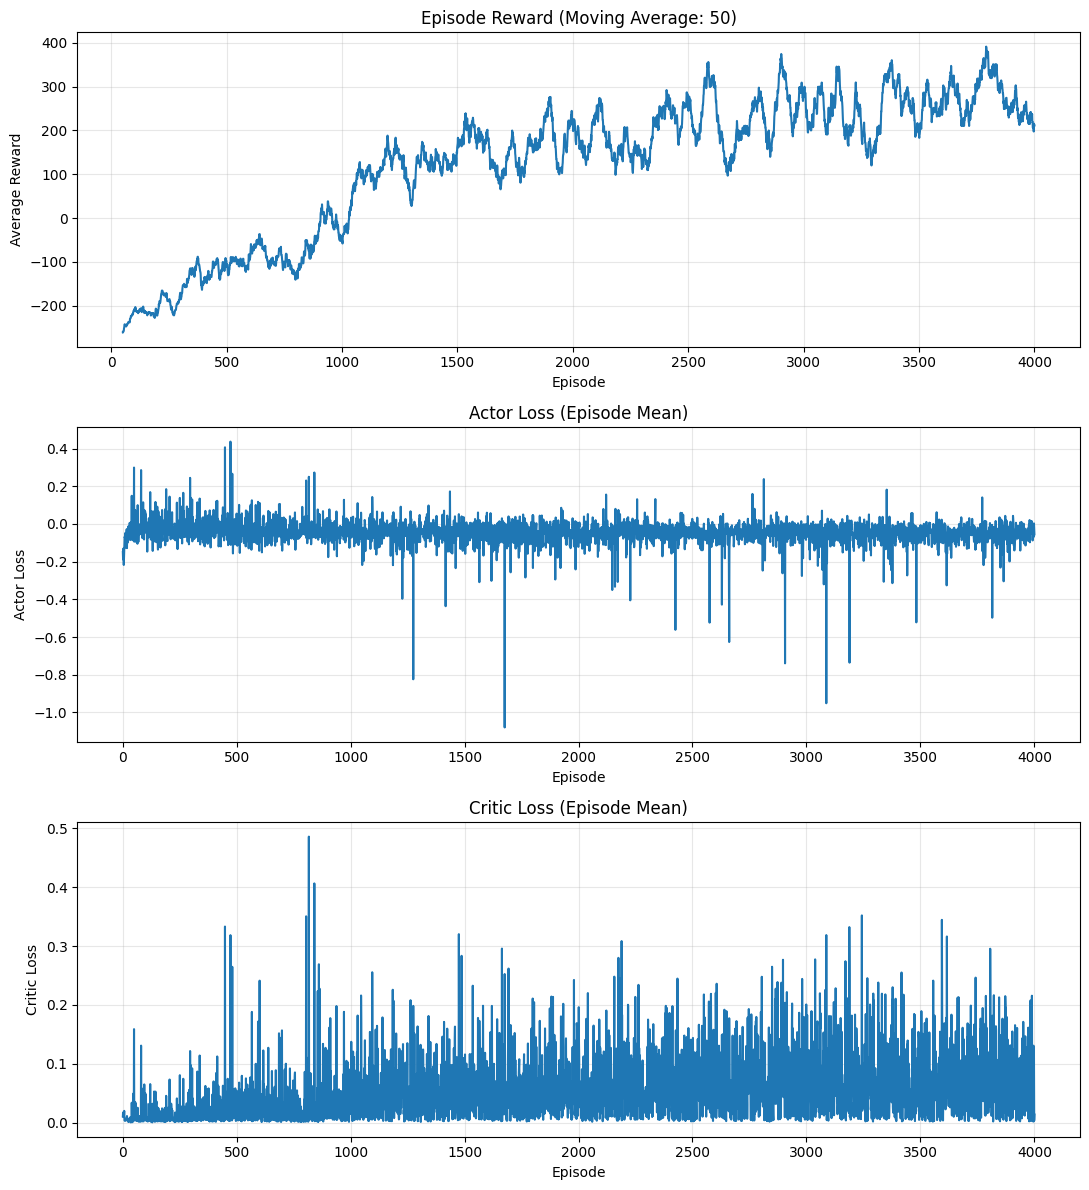

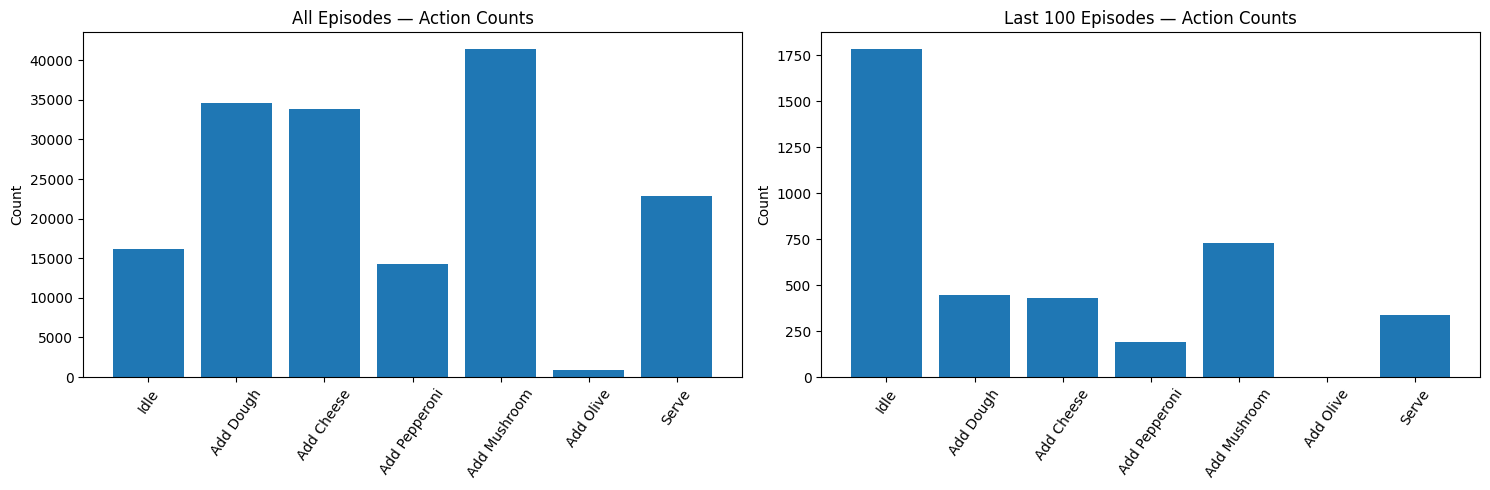

=== Last 100 Episodes Action Distribution ===
Idle            :  45.56%
Add Dough       :  11.38%
Add Cheese      :  11.02%
Add Pepperoni   :   4.80%
Add Mushroom    :  18.62%
Add Olive       :   0.00%
Serve           :   8.62%


In [ ]:
# 1. Imports & Hyperparameters
import random
import shutil
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym
from gymnasium import spaces
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.distributions import Categorical

SEED = 123
NUM_EPISODES = 4000
LEARNING_RATE = 0.0002
GAMMA = 0.98
N_ROLLOUT = 10
REWARD_SCALE = 100.0
ENTROPY_COEF = 0.01
SHAPING_REWARD = 5.0 # ⭐ 올바른 재료 추가 시 +5
COMPLETION_SHAPING_REWARD = 10.0 # ⭐ 주문에 필요한 마지막 재료를 추가하여 피자를 완성하면 +10

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

# 2. Pizza Shop Environment
class PizzaShopEnv(gym.Env):
    def __init__(self):
        super().__init__()
        self.max_orders = 4
        self.max_steps = 100
        self.menus = {
            1: [1, 1, 0, 0, 0],  # Cheese
            2: [1, 1, 1, 0, 0],  # Pepperoni
            3: [1, 1, 0, 1, 0],  # Mushroom
            4: [1, 1, 1, 1, 1],  # Special
        }
        # 0 Idle, 1 Dough, 2 Cheese, 3 Pepperoni, 4 Mushroom, 5 Olive, 6 Serve
        self.action_space = spaces.Discrete(7)
        self.observation_space = spaces.Box(
            low=np.zeros(13, dtype=np.float32),
            high=np.array([1, 1, 1, 1, 1, 4, 1, 4, 1, 4, 1, 4, 1], dtype=np.float32),
            dtype=np.float32,
        )
        self.counter = np.zeros(5, dtype=np.float32)
        self.orders = []
        self.steps = 0

    def _get_obs(self):
        obs = list(self.counter)
        for i in range(self.max_orders):
            if i < len(self.orders):
                obs.extend([self.orders[i]['menu'], self.orders[i]['timer'] / 48.0])
            else:
                obs.extend([0, 0])
        return np.array(obs, dtype=np.float32)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.counter = np.zeros(5, dtype=np.float32)
        self.orders = [
            {'menu': int(self.np_random.choice([1, 2, 3, 4])),
             'timer': int(self.np_random.integers(36, 49))}
            for _ in range(self.max_orders)
        ]
        self.steps = 0
        return self._get_obs(), {}

    def _next_required_ingredient(self):
        if not self.orders:
            return None
        expected = self.menus[self.orders[0]['menu']]
        for idx, needed in enumerate(expected):
            if needed == 1 and self.counter[idx] == 0:
                return idx
        return None

    def step(self, action):
        action = int(action)
        reward = -0.1
        success_count = 0
        timeout_count = 0
        self.steps += 1
        next_required = self._next_required_ingredient()

        if action == 0:
            pass
        elif action == 1:  # Dough
            if self.counter[0] == 0:
                self.counter[0] = 1
                if next_required == 0:
                    reward += (COMPLETION_SHAPING_REWARD
                               if np.array_equal(self.counter, self.menus[self.orders[0]['menu']])
                               else SHAPING_REWARD)
            else:
                reward -= 2
        elif action == 2:  # Cheese
            if self.counter[0] == 1 and self.counter[1] == 0:
                self.counter[1] = 1
                if next_required == 1:
                    reward += (COMPLETION_SHAPING_REWARD
                               if np.array_equal(self.counter, self.menus[self.orders[0]['menu']])
                               else SHAPING_REWARD)
            else:
                reward -= 2
        elif action in (3, 4, 5):  # Toppings
            idx = action - 1
            if self.counter[0] == 1 and self.counter[1] == 1 and self.counter[idx] == 0:
                self.counter[idx] = 1
                if next_required == idx:
                    reward += (COMPLETION_SHAPING_REWARD
                               if np.array_equal(self.counter, self.menus[self.orders[0]['menu']])
                               else SHAPING_REWARD)
            else:
                reward -= 2
        elif action == 6:  # Serve (FIFO)
            if self.orders:
                expected = self.menus[self.orders[0]['menu']]
                if np.array_equal(self.counter, expected):
                    reward += 150
                    success_count += 1
                    self.orders.pop(0)
                else:
                    reward -= 15
                self.counter = np.zeros(5, dtype=np.float32)

        # Every active order loses one step, including on a serve action.
        for order in self.orders:
            order['timer'] -= 1
        remaining = []
        for order in self.orders:
            if order['timer'] <= 0:
                reward -= 50
                timeout_count += 1
            else:
                remaining.append(order)
        self.orders = remaining

        terminated = len(self.orders) == 0
        truncated = self.steps >= self.max_steps and not terminated
        info = {'success_count': success_count, 'timeout_count': timeout_count}
        return self._get_obs(), reward, terminated, truncated, info

# 3. Shared-Network Actor-Critic
class ActorCritic(nn.Module):
    def __init__(self, state_dim=13, action_dim=7):
        super().__init__()
        self.data = []
        self.fc1 = nn.Linear(state_dim, 256)
        self.fc_pi = nn.Linear(256, action_dim)
        self.fc_v = nn.Linear(256, 1)
        self.optimizer = optim.Adam(self.parameters(), lr=LEARNING_RATE)

    def pi(self, x, softmax_dim=-1):
        x = F.relu(self.fc1(x))
        return F.softmax(self.fc_pi(x), dim=softmax_dim)

    def v(self, x):
        x = F.relu(self.fc1(x))
        return self.fc_v(x)

    def put_data(self, transition):
        self.data.append(transition)

    def make_batch(self):
        s_lst, a_lst, r_lst, s_prime_lst, terminal_lst = [], [], [], [], []
        for s, a, r, s_prime, terminated in self.data:
            s_lst.append(s)
            a_lst.append([a])
            r_lst.append([r / REWARD_SCALE])
            s_prime_lst.append(s_prime)
            terminal_lst.append([0.0 if terminated else 1.0])
        self.data = []
        s = torch.as_tensor(np.asarray(s_lst), dtype=torch.float32, device=device)
        a = torch.as_tensor(a_lst, dtype=torch.long, device=device)
        r = torch.as_tensor(r_lst, dtype=torch.float32, device=device)
        s_prime = torch.as_tensor(np.asarray(s_prime_lst), dtype=torch.float32, device=device)
        mask = torch.as_tensor(terminal_lst, dtype=torch.float32, device=device)
        return s, a, r, s_prime, mask

    def train_net(self):
        if not self.data:
            return None, None
        s, a, r, s_prime, mask = self.make_batch()
        # 10개 전이를 모아도 TD target은 각 전이에 대한 1-step target임
        with torch.no_grad():
            td_target = r + GAMMA * self.v(s_prime) * mask
        value = self.v(s)
        delta = td_target - value
        pi = self.pi(s, softmax_dim=1)
        pi_a = pi.gather(1, a).clamp_min(1e-8)
        entropy = Categorical(probs=pi).entropy().mean()
        actor_loss = (-torch.log(pi_a) * delta.detach()).mean() - ENTROPY_COEF * entropy
        critic_loss = F.smooth_l1_loss(value, td_target)
        loss = actor_loss + critic_loss

        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()
        return actor_loss.mean().item(), critic_loss.item()

# 4. Initialize & Checkpoint Setup
env = PizzaShopEnv()
env.reset(seed=SEED)
model = ActorCritic().to(device)
CHECKPOINT_DIR = Path('actor_critic_test_2_seed123_checkpoints')
CHECKPOINT_DIR.mkdir(exist_ok=True)

def save_checkpoint(episode):
    path = CHECKPOINT_DIR / f'actor_critic_test_2_seed123_ep{episode}.pth'
    torch.save(model.state_dict(), path)
    print(f'Checkpoint saved: episode {episode} -> {path}')

save_checkpoint(0)

# 5. Training — 10-transition mini-batches, 1-step TD
# Gymnasium: terminated는 진짜 종료, truncated는 시간 제한 종료.
# truncated에서는 에피소드를 멈추되 TD target의 다음 상태 가치는 bootstrap 가능하도록 유지.
episode_rewards, episode_successes, episode_timeouts = [], [], []
episode_actor_losses, episode_critic_losses = [], []
action_counts = np.zeros(7, dtype=np.int64)
all_episode_actions = []

for episode in range(1, NUM_EPISODES + 1):
    state, _ = env.reset()
    done = False
    total_reward, successes, timeouts = 0.0, 0, 0
    actor_losses, critic_losses, actions_this_episode = [], [], []

    while not done:
        for t in range(N_ROLLOUT):
            with torch.no_grad():
                state_tensor = torch.as_tensor(state, dtype=torch.float32, device=device)
                probs = model.pi(state_tensor)
                action = int(Categorical(probs).sample().item())

            next_state, reward, terminated, truncated, info = env.step(action)
            model.put_data((state, action, reward, next_state, terminated))
            action_counts[action] += 1
            actions_this_episode.append(action)
            total_reward += reward  # 보고용 점수는 원래 보상 단위로 기록
            successes += info['success_count']
            timeouts += info['timeout_count']
            state = next_state
            done = terminated or truncated
            if done:
                break

        actor_loss, critic_loss = model.train_net()
        if actor_loss is not None:
            actor_losses.append(actor_loss)
            critic_losses.append(critic_loss)

    episode_rewards.append(total_reward)
    episode_successes.append(successes)
    episode_timeouts.append(timeouts)
    episode_actor_losses.append(float(np.mean(actor_losses)))
    episode_critic_losses.append(float(np.mean(critic_losses)))
    all_episode_actions.append(actions_this_episode)

    if episode % 50 == 0:
        print(f'Episode {episode:4d} | Avg Reward (50): {np.mean(episode_rewards[-50:]):8.2f} '
              f'| Success: {successes} | Timeout: {timeouts}')
    if episode in (500, 1000, 2000, 3000, 4000):
        save_checkpoint(episode)

last_100_action_counts = np.zeros(7, dtype=np.int64)
for actions in all_episode_actions[-100:]:
    for a in actions:
        last_100_action_counts[a] += 1

# 6. Results
last_100_success = sum(episode_successes[-100:])
last_100_timeout = sum(episode_timeouts[-100:])
last_100_orders = last_100_success + last_100_timeout
total_success = sum(episode_successes)
total_timeout = sum(episode_timeouts)
total_orders = total_success + total_timeout

print('=== Actor-Critic Experiment test-2 (Seed 123, Entropy 0.01, Reward Shaping +5 / Completion +10) ===')
print(f'Last 100 Episodes Average Reward: {np.mean(episode_rewards[-100:]):.2f}')
print(f'Last 50 Episodes Average Reward: {np.mean(episode_rewards[-50:]):.2f}')
print(f'Overall Success: {total_success}/{total_orders} ({100*total_success/total_orders if total_orders else 0:.2f}%)')
print(f'Overall Timeout: {total_timeout}/{total_orders} ({100*total_timeout/total_orders if total_orders else 0:.2f}%)')
print(f'Last 100 Episodes Order Success Rate: {last_100_success}/{last_100_orders} ({100*last_100_success/last_100_orders if last_100_orders else 0:.2f}%)')
print(f'Last 100 Episodes Average Actor Loss: {np.mean(episode_actor_losses[-100:]):.4f}')
print(f'Last 100 Episodes Average Critic Loss: {np.mean(episode_critic_losses[-100:]):.4f}')

# 7. Learning Curves
def moving_average(values, window=50):
    return np.convolve(np.asarray(values, dtype=np.float64), np.ones(window) / window, mode='valid')

fig, axes = plt.subplots(3, 1, figsize=(11, 12))
axes[0].plot(np.arange(50, NUM_EPISODES + 1), moving_average(episode_rewards, 50))
axes[0].set_title('Episode Reward (Moving Average: 50)')
axes[0].set_xlabel('Episode')
axes[0].set_ylabel('Average Reward')
axes[1].plot(range(1, NUM_EPISODES + 1), episode_actor_losses)
axes[1].set_title('Actor Loss (Episode Mean)')
axes[1].set_xlabel('Episode')
axes[1].set_ylabel('Actor Loss')
axes[2].plot(range(1, NUM_EPISODES + 1), episode_critic_losses)
axes[2].set_title('Critic Loss (Episode Mean)')
axes[2].set_xlabel('Episode')
axes[2].set_ylabel('Critic Loss')
for ax in axes: ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 8. Action Distribution
names = ['Idle', 'Add Dough', 'Add Cheese', 'Add Pepperoni',
         'Add Mushroom', 'Add Olive', 'Serve']
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].bar(names, action_counts)
axes[0].set_title('All Episodes — Action Counts')
axes[0].set_ylabel('Count')
axes[1].bar(names, last_100_action_counts)
axes[1].set_title('Last 100 Episodes — Action Counts')
axes[1].set_ylabel('Count')
for ax in axes: ax.tick_params(axis='x', rotation=55)
plt.tight_layout()
plt.show()

last_total = last_100_action_counts.sum()
print('=== Last 100 Episodes Action Distribution ===')
for name, count in zip(names, last_100_action_counts):
    print(f'{name:16s}: {100*count/last_total if last_total else 0:6.2f}%')


### 추가 분석: 메뉴별 주문 처리 성공률

- 학습된 모델을 이용해 100개 에피소드 평가
- 치즈, 페퍼로니, 버섯, 스페셜 메뉴별 주문 수 및 성공 건수 확인
- 메뉴별 주문 처리 성공률을 비교하여 실패가 집중되는 메뉴 분석

=== Menu-wise Order Success Rate (100 Evaluation Episodes, Seed 42) ===
Menu           Orders   Success   Timeout   Success Rate
Cheese             93        61        32         65.59%
Pepperoni          99        60        39         60.61%
Mushroom          102        77        25         75.49%
Special           106         0       106          0.00%
Total: 198/400 (49.50%)


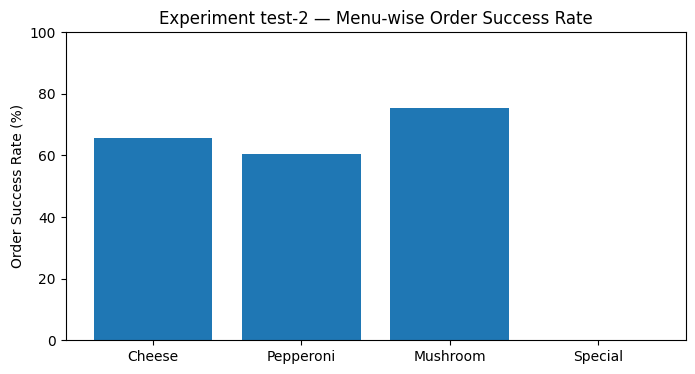

In [ ]:
# 10. Menu-wise Order Success Analysis
MENU_NAMES = {1: 'Cheese', 2: 'Pepperoni', 3: 'Mushroom', 4: 'Special'}
EVAL_EPISODES = 100
EVAL_SEED = 42

# 기존 model을 초기화하거나 학습하지 않고, 저장된 최종 가중치를 별도 모델에 불러옴
eval_model = ActorCritic().to(device)
eval_path = CHECKPOINT_DIR / 'actor_critic_test_2_seed123_ep4000.pth'
eval_model.load_state_dict(torch.load(eval_path, map_location=device, weights_only=True))
eval_model.eval()

torch.manual_seed(EVAL_SEED)  # 평가 행동 샘플링 재현성

menu_stats = {menu: {'orders': 0, 'success': 0, 'timeout': 0} for menu in MENU_NAMES}
eval_env = PizzaShopEnv()

for ep in range(EVAL_EPISODES):
    state, _ = eval_env.reset(seed=EVAL_SEED if ep == 0 else None)
    for order in eval_env.orders:
        menu_stats[order['menu']]['orders'] += 1

    done = False
    while not done:
        before_orders = [order.copy() for order in eval_env.orders]
        with torch.no_grad():
            probs = eval_model.pi(torch.as_tensor(state, dtype=torch.float32, device=device))
            action = int(Categorical(probs=probs).sample().item())

        next_state, reward, terminated, truncated, info = eval_env.step(action)

        # 성공한 서빙은 FIFO 첫 주문에 해당함
        if info['success_count']:
            menu_stats[before_orders[0]['menu']]['success'] += 1

        # 성공한 주문을 제외하고 타이머가 0이 된 주문을 메뉴별로 집계함
        remaining_before_timeout = before_orders[info['success_count']:]
        for order in remaining_before_timeout:
            if order['timer'] - 1 <= 0:
                menu_stats[order['menu']]['timeout'] += 1

        state = next_state
        done = terminated or truncated

print(f'=== Menu-wise Order Success Rate ({EVAL_EPISODES} Evaluation Episodes, Seed {EVAL_SEED}) ===')
print(f'{"Menu":<12} {"Orders":>8} {"Success":>9} {"Timeout":>9} {"Success Rate":>14}')
for menu, name in MENU_NAMES.items():
    result = menu_stats[menu]
    rate = 100 * result['success'] / result['orders'] if result['orders'] else 0
    print(f'{name:<12} {result["orders"]:>8} {result["success"]:>9} {result["timeout"]:>9} {rate:>13.2f}%')

all_orders = sum(x['orders'] for x in menu_stats.values())
all_success = sum(x['success'] for x in menu_stats.values())
print(f'Total: {all_success}/{all_orders} ({100 * all_success / all_orders:.2f}%)')

plt.figure(figsize=(8, 4))
plt.bar([MENU_NAMES[m] for m in MENU_NAMES],
        [100 * menu_stats[m]['success'] / menu_stats[m]['orders'] if menu_stats[m]['orders'] else 0 for m in MENU_NAMES])
plt.ylabel('Order Success Rate (%)')
plt.ylim(0, 100)
plt.title('Experiment test-2 — Menu-wise Order Success Rate')
plt.show()

#### **추가 test-2 결과 분석 (Seed 123)**

마지막 100에피소드에서 주문 처리 성공률 49.50%, 평균 보상 216.03을 기록하였으며, 학습 후반에도 평균 보상의 변동이 지속적으로 나타남.

동일한 평가 시드(42)를 적용한 별도 평가에서는 전체 주문 처리 성공률 49.50%, 스페셜 피자 성공률 0.00%를 기록함.

또한 Idle 행동 비율은 45.56%, Olive 추가 행동 비율은 0.00%로 나타났으며, 기존 추가 test-1과 유사하게 Olive 행동의 학습 부족 현상이 관찰됨.

####
## 4-4. 추가 test-3 (Seed 2026)

Device: cpu
Checkpoint saved: episode 0 -> actor_critic_test_3_seed2026_checkpoints/actor_critic_test_3_seed2026_ep0.pth
Episode   50 | Avg Reward (50):  -281.73 | Success: 0 | Timeout: 4
Episode  100 | Avg Reward (50):  -265.33 | Success: 0 | Timeout: 4
Episode  150 | Avg Reward (50):  -236.37 | Success: 0 | Timeout: 4
Episode  200 | Avg Reward (50):  -248.00 | Success: 0 | Timeout: 4
Episode  250 | Avg Reward (50):  -245.85 | Success: 0 | Timeout: 4
Episode  300 | Avg Reward (50):  -232.22 | Success: 0 | Timeout: 4
Episode  350 | Avg Reward (50):  -240.73 | Success: 0 | Timeout: 4
Episode  400 | Avg Reward (50):  -232.65 | Success: 0 | Timeout: 4
Episode  450 | Avg Reward (50):  -231.19 | Success: 0 | Timeout: 4
Episode  500 | Avg Reward (50):  -214.17 | Success: 0 | Timeout: 4
Checkpoint saved: episode 500 -> actor_critic_test_3_seed2026_checkpoints/actor_critic_test_3_seed2026_ep500.pth
Episode  550 | Avg Reward (50):  -199.37 | Success: 1 | Timeout: 3
Episode  600 | Avg Reward (50

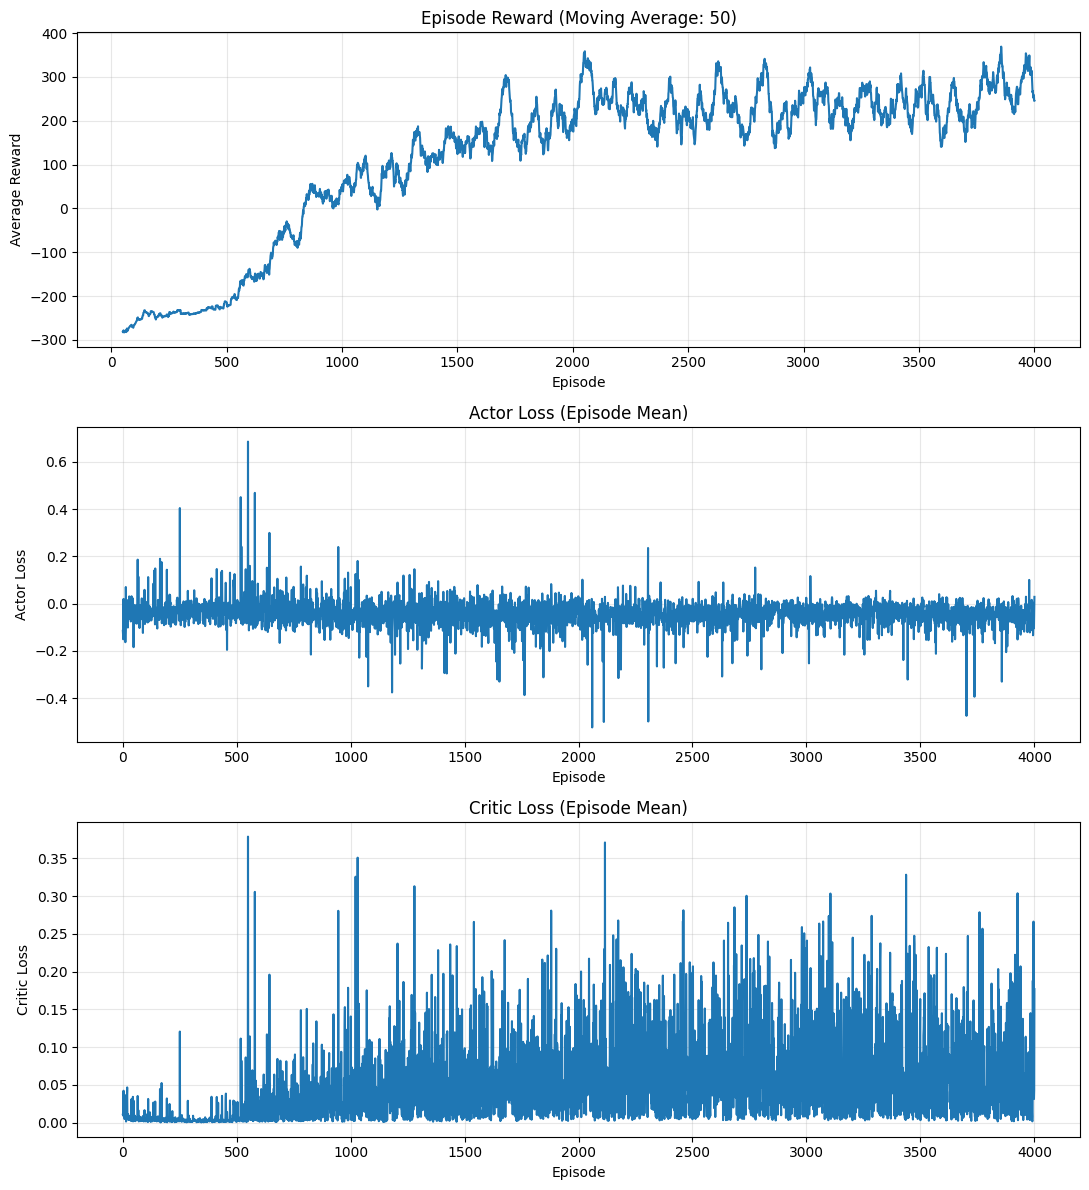

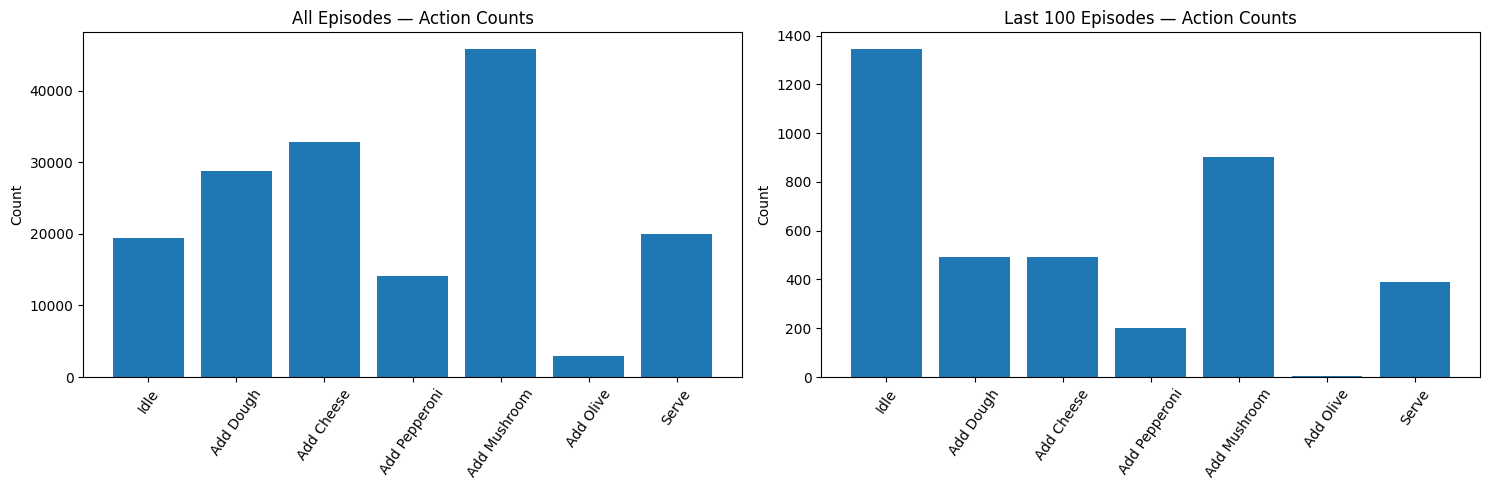

=== Last 100 Episodes Action Distribution ===
Idle            :  35.20%
Add Dough       :  12.84%
Add Cheese      :  12.84%
Add Pepperoni   :   5.26%
Add Mushroom    :  23.59%
Add Olive       :   0.08%
Serve           :  10.20%


In [ ]:
# 1. Imports & Hyperparameters
import random
import shutil
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym
from gymnasium import spaces
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.distributions import Categorical

SEED = 2026
NUM_EPISODES = 4000
LEARNING_RATE = 0.0002
GAMMA = 0.98
N_ROLLOUT = 10
REWARD_SCALE = 100.0
ENTROPY_COEF = 0.01
SHAPING_REWARD = 5.0 # ⭐ 올바른 재료 추가 시 +5
COMPLETION_SHAPING_REWARD = 10.0 # ⭐ 주문에 필요한 마지막 재료를 추가하여 피자를 완성하면 +10

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

# 2. Pizza Shop Environment
class PizzaShopEnv(gym.Env):
    def __init__(self):
        super().__init__()
        self.max_orders = 4
        self.max_steps = 100
        self.menus = {
            1: [1, 1, 0, 0, 0],  # Cheese
            2: [1, 1, 1, 0, 0],  # Pepperoni
            3: [1, 1, 0, 1, 0],  # Mushroom
            4: [1, 1, 1, 1, 1],  # Special
        }
        # 0 Idle, 1 Dough, 2 Cheese, 3 Pepperoni, 4 Mushroom, 5 Olive, 6 Serve
        self.action_space = spaces.Discrete(7)
        self.observation_space = spaces.Box(
            low=np.zeros(13, dtype=np.float32),
            high=np.array([1, 1, 1, 1, 1, 4, 1, 4, 1, 4, 1, 4, 1], dtype=np.float32),
            dtype=np.float32,
        )
        self.counter = np.zeros(5, dtype=np.float32)
        self.orders = []
        self.steps = 0

    def _get_obs(self):
        obs = list(self.counter)
        for i in range(self.max_orders):
            if i < len(self.orders):
                obs.extend([self.orders[i]['menu'], self.orders[i]['timer'] / 48.0])
            else:
                obs.extend([0, 0])
        return np.array(obs, dtype=np.float32)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.counter = np.zeros(5, dtype=np.float32)
        self.orders = [
            {'menu': int(self.np_random.choice([1, 2, 3, 4])),
             'timer': int(self.np_random.integers(36, 49))}
            for _ in range(self.max_orders)
        ]
        self.steps = 0
        return self._get_obs(), {}

    def _next_required_ingredient(self):
        if not self.orders:
            return None
        expected = self.menus[self.orders[0]['menu']]
        for idx, needed in enumerate(expected):
            if needed == 1 and self.counter[idx] == 0:
                return idx
        return None

    def step(self, action):
        action = int(action)
        reward = -0.1
        success_count = 0
        timeout_count = 0
        self.steps += 1
        next_required = self._next_required_ingredient()

        if action == 0:
            pass
        elif action == 1:  # Dough
            if self.counter[0] == 0:
                self.counter[0] = 1
                if next_required == 0:
                    reward += (COMPLETION_SHAPING_REWARD
                               if np.array_equal(self.counter, self.menus[self.orders[0]['menu']])
                               else SHAPING_REWARD)
            else:
                reward -= 2
        elif action == 2:  # Cheese
            if self.counter[0] == 1 and self.counter[1] == 0:
                self.counter[1] = 1
                if next_required == 1:
                    reward += (COMPLETION_SHAPING_REWARD
                               if np.array_equal(self.counter, self.menus[self.orders[0]['menu']])
                               else SHAPING_REWARD)
            else:
                reward -= 2
        elif action in (3, 4, 5):  # Toppings
            idx = action - 1
            if self.counter[0] == 1 and self.counter[1] == 1 and self.counter[idx] == 0:
                self.counter[idx] = 1
                if next_required == idx:
                    reward += (COMPLETION_SHAPING_REWARD
                               if np.array_equal(self.counter, self.menus[self.orders[0]['menu']])
                               else SHAPING_REWARD)
            else:
                reward -= 2
        elif action == 6:  # Serve (FIFO)
            if self.orders:
                expected = self.menus[self.orders[0]['menu']]
                if np.array_equal(self.counter, expected):
                    reward += 150
                    success_count += 1
                    self.orders.pop(0)
                else:
                    reward -= 15
                self.counter = np.zeros(5, dtype=np.float32)

        # Every active order loses one step, including on a serve action.
        for order in self.orders:
            order['timer'] -= 1
        remaining = []
        for order in self.orders:
            if order['timer'] <= 0:
                reward -= 50
                timeout_count += 1
            else:
                remaining.append(order)
        self.orders = remaining

        terminated = len(self.orders) == 0
        truncated = self.steps >= self.max_steps and not terminated
        info = {'success_count': success_count, 'timeout_count': timeout_count}
        return self._get_obs(), reward, terminated, truncated, info

# 3. Shared-Network Actor-Critic
class ActorCritic(nn.Module):
    def __init__(self, state_dim=13, action_dim=7):
        super().__init__()
        self.data = []
        self.fc1 = nn.Linear(state_dim, 256)
        self.fc_pi = nn.Linear(256, action_dim)
        self.fc_v = nn.Linear(256, 1)
        self.optimizer = optim.Adam(self.parameters(), lr=LEARNING_RATE)

    def pi(self, x, softmax_dim=-1):
        x = F.relu(self.fc1(x))
        return F.softmax(self.fc_pi(x), dim=softmax_dim)

    def v(self, x):
        x = F.relu(self.fc1(x))
        return self.fc_v(x)

    def put_data(self, transition):
        self.data.append(transition)

    def make_batch(self):
        s_lst, a_lst, r_lst, s_prime_lst, terminal_lst = [], [], [], [], []
        for s, a, r, s_prime, terminated in self.data:
            s_lst.append(s)
            a_lst.append([a])
            r_lst.append([r / REWARD_SCALE])
            s_prime_lst.append(s_prime)
            terminal_lst.append([0.0 if terminated else 1.0])
        self.data = []
        s = torch.as_tensor(np.asarray(s_lst), dtype=torch.float32, device=device)
        a = torch.as_tensor(a_lst, dtype=torch.long, device=device)
        r = torch.as_tensor(r_lst, dtype=torch.float32, device=device)
        s_prime = torch.as_tensor(np.asarray(s_prime_lst), dtype=torch.float32, device=device)
        mask = torch.as_tensor(terminal_lst, dtype=torch.float32, device=device)
        return s, a, r, s_prime, mask

    def train_net(self):
        if not self.data:
            return None, None
        s, a, r, s_prime, mask = self.make_batch()
        # 10개 전이를 모아도 TD target은 각 전이에 대한 1-step target임
        with torch.no_grad():
            td_target = r + GAMMA * self.v(s_prime) * mask
        value = self.v(s)
        delta = td_target - value
        pi = self.pi(s, softmax_dim=1)
        pi_a = pi.gather(1, a).clamp_min(1e-8)
        entropy = Categorical(probs=pi).entropy().mean()
        actor_loss = (-torch.log(pi_a) * delta.detach()).mean() - ENTROPY_COEF * entropy
        critic_loss = F.smooth_l1_loss(value, td_target)
        loss = actor_loss + critic_loss

        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()
        return actor_loss.mean().item(), critic_loss.item()

# 4. Initialize & Checkpoint Setup
env = PizzaShopEnv()
env.reset(seed=SEED)
model = ActorCritic().to(device)
CHECKPOINT_DIR = Path('actor_critic_test_3_seed2026_checkpoints')
CHECKPOINT_DIR.mkdir(exist_ok=True)

def save_checkpoint(episode):
    path = CHECKPOINT_DIR / f'actor_critic_test_3_seed2026_ep{episode}.pth'
    torch.save(model.state_dict(), path)
    print(f'Checkpoint saved: episode {episode} -> {path}')

save_checkpoint(0)

# 5. Training — 10-transition mini-batches, 1-step TD
# Gymnasium: terminated는 진짜 종료, truncated는 시간 제한 종료.
# truncated에서는 에피소드를 멈추되 TD target의 다음 상태 가치는 bootstrap 가능하도록 유지.
episode_rewards, episode_successes, episode_timeouts = [], [], []
episode_actor_losses, episode_critic_losses = [], []
action_counts = np.zeros(7, dtype=np.int64)
all_episode_actions = []

for episode in range(1, NUM_EPISODES + 1):
    state, _ = env.reset()
    done = False
    total_reward, successes, timeouts = 0.0, 0, 0
    actor_losses, critic_losses, actions_this_episode = [], [], []

    while not done:
        for t in range(N_ROLLOUT):
            with torch.no_grad():
                state_tensor = torch.as_tensor(state, dtype=torch.float32, device=device)
                probs = model.pi(state_tensor)
                action = int(Categorical(probs).sample().item())

            next_state, reward, terminated, truncated, info = env.step(action)
            model.put_data((state, action, reward, next_state, terminated))
            action_counts[action] += 1
            actions_this_episode.append(action)
            total_reward += reward  # 보고용 점수는 원래 보상 단위로 기록
            successes += info['success_count']
            timeouts += info['timeout_count']
            state = next_state
            done = terminated or truncated
            if done:
                break

        actor_loss, critic_loss = model.train_net()
        if actor_loss is not None:
            actor_losses.append(actor_loss)
            critic_losses.append(critic_loss)

    episode_rewards.append(total_reward)
    episode_successes.append(successes)
    episode_timeouts.append(timeouts)
    episode_actor_losses.append(float(np.mean(actor_losses)))
    episode_critic_losses.append(float(np.mean(critic_losses)))
    all_episode_actions.append(actions_this_episode)

    if episode % 50 == 0:
        print(f'Episode {episode:4d} | Avg Reward (50): {np.mean(episode_rewards[-50:]):8.2f} '
              f'| Success: {successes} | Timeout: {timeouts}')
    if episode in (500, 1000, 2000, 3000, 4000):
        save_checkpoint(episode)

last_100_action_counts = np.zeros(7, dtype=np.int64)
for actions in all_episode_actions[-100:]:
    for a in actions:
        last_100_action_counts[a] += 1

# 6. Results
last_100_success = sum(episode_successes[-100:])
last_100_timeout = sum(episode_timeouts[-100:])
last_100_orders = last_100_success + last_100_timeout
total_success = sum(episode_successes)
total_timeout = sum(episode_timeouts)
total_orders = total_success + total_timeout

print('=== Actor-Critic Experiment test-3 (Seed 2026, Entropy 0.01, Reward Shaping +5 / Completion +10) ===')
print(f'Last 100 Episodes Average Reward: {np.mean(episode_rewards[-100:]):.2f}')
print(f'Last 50 Episodes Average Reward: {np.mean(episode_rewards[-50:]):.2f}')
print(f'Overall Success: {total_success}/{total_orders} ({100*total_success/total_orders if total_orders else 0:.2f}%)')
print(f'Overall Timeout: {total_timeout}/{total_orders} ({100*total_timeout/total_orders if total_orders else 0:.2f}%)')
print(f'Last 100 Episodes Order Success Rate: {last_100_success}/{last_100_orders} ({100*last_100_success/last_100_orders if last_100_orders else 0:.2f}%)')
print(f'Last 100 Episodes Average Actor Loss: {np.mean(episode_actor_losses[-100:]):.4f}')
print(f'Last 100 Episodes Average Critic Loss: {np.mean(episode_critic_losses[-100:]):.4f}')

# 7. Learning Curves
def moving_average(values, window=50):
    return np.convolve(np.asarray(values, dtype=np.float64), np.ones(window) / window, mode='valid')

fig, axes = plt.subplots(3, 1, figsize=(11, 12))
axes[0].plot(np.arange(50, NUM_EPISODES + 1), moving_average(episode_rewards, 50))
axes[0].set_title('Episode Reward (Moving Average: 50)')
axes[0].set_xlabel('Episode')
axes[0].set_ylabel('Average Reward')
axes[1].plot(range(1, NUM_EPISODES + 1), episode_actor_losses)
axes[1].set_title('Actor Loss (Episode Mean)')
axes[1].set_xlabel('Episode')
axes[1].set_ylabel('Actor Loss')
axes[2].plot(range(1, NUM_EPISODES + 1), episode_critic_losses)
axes[2].set_title('Critic Loss (Episode Mean)')
axes[2].set_xlabel('Episode')
axes[2].set_ylabel('Critic Loss')
for ax in axes: ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 8. Action Distribution
names = ['Idle', 'Add Dough', 'Add Cheese', 'Add Pepperoni',
         'Add Mushroom', 'Add Olive', 'Serve']
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].bar(names, action_counts)
axes[0].set_title('All Episodes — Action Counts')
axes[0].set_ylabel('Count')
axes[1].bar(names, last_100_action_counts)
axes[1].set_title('Last 100 Episodes — Action Counts')
axes[1].set_ylabel('Count')
for ax in axes: ax.tick_params(axis='x', rotation=55)
plt.tight_layout()
plt.show()

last_total = last_100_action_counts.sum()
print('=== Last 100 Episodes Action Distribution ===')
for name, count in zip(names, last_100_action_counts):
    print(f'{name:16s}: {100*count/last_total if last_total else 0:6.2f}%')


### 추가 분석: 메뉴별 주문 처리 성공률

- 학습된 모델을 이용해 100개 에피소드 평가
- 치즈, 페퍼로니, 버섯, 스페셜 메뉴별 주문 수 및 성공 건수 확인
- 메뉴별 주문 처리 성공률을 비교하여 실패가 집중되는 메뉴 분석

=== Menu-wise Order Success Rate (100 Evaluation Episodes, Seed 42) ===
Menu           Orders   Success   Timeout   Success Rate
Cheese             93        59        34         63.44%
Pepperoni          99        56        43         56.57%
Mushroom          102        74        28         72.55%
Special           106         0       106          0.00%
Total: 189/400 (47.25%)


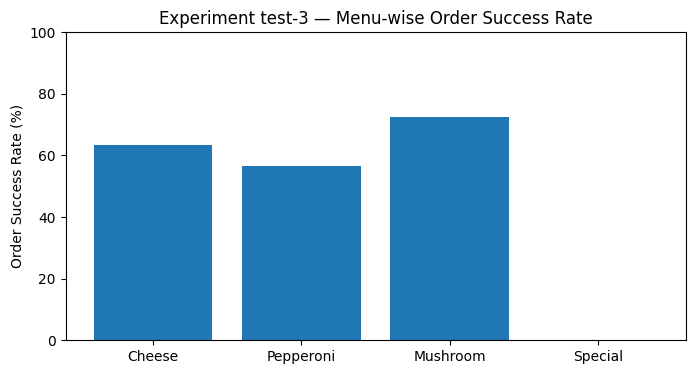

In [ ]:
# 10. Menu-wise Order Success Analysis
MENU_NAMES = {1: 'Cheese', 2: 'Pepperoni', 3: 'Mushroom', 4: 'Special'}
EVAL_EPISODES = 100
EVAL_SEED = 42

# 기존 model을 초기화하거나 학습하지 않고, 저장된 최종 가중치를 별도 모델에 불러옴
eval_model = ActorCritic().to(device)
eval_path = CHECKPOINT_DIR / 'actor_critic_test_3_seed2026_ep4000.pth'
eval_model.load_state_dict(torch.load(eval_path, map_location=device, weights_only=True))
eval_model.eval()

torch.manual_seed(EVAL_SEED)  # 평가 행동 샘플링 재현성

menu_stats = {menu: {'orders': 0, 'success': 0, 'timeout': 0} for menu in MENU_NAMES}
eval_env = PizzaShopEnv()

for ep in range(EVAL_EPISODES):
    state, _ = eval_env.reset(seed=EVAL_SEED if ep == 0 else None)
    for order in eval_env.orders:
        menu_stats[order['menu']]['orders'] += 1

    done = False
    while not done:
        before_orders = [order.copy() for order in eval_env.orders]
        with torch.no_grad():
            probs = eval_model.pi(torch.as_tensor(state, dtype=torch.float32, device=device))
            action = int(Categorical(probs=probs).sample().item())

        next_state, reward, terminated, truncated, info = eval_env.step(action)

        # 성공한 서빙은 FIFO 첫 주문에 해당함
        if info['success_count']:
            menu_stats[before_orders[0]['menu']]['success'] += 1

        # 성공한 주문을 제외하고 타이머가 0이 된 주문을 메뉴별로 집계함
        remaining_before_timeout = before_orders[info['success_count']:]
        for order in remaining_before_timeout:
            if order['timer'] - 1 <= 0:
                menu_stats[order['menu']]['timeout'] += 1

        state = next_state
        done = terminated or truncated

print(f'=== Menu-wise Order Success Rate ({EVAL_EPISODES} Evaluation Episodes, Seed {EVAL_SEED}) ===')
print(f'{"Menu":<12} {"Orders":>8} {"Success":>9} {"Timeout":>9} {"Success Rate":>14}')
for menu, name in MENU_NAMES.items():
    result = menu_stats[menu]
    rate = 100 * result['success'] / result['orders'] if result['orders'] else 0
    print(f'{name:<12} {result["orders"]:>8} {result["success"]:>9} {result["timeout"]:>9} {rate:>13.2f}%')

all_orders = sum(x['orders'] for x in menu_stats.values())
all_success = sum(x['success'] for x in menu_stats.values())
print(f'Total: {all_success}/{all_orders} ({100 * all_success / all_orders:.2f}%)')

plt.figure(figsize=(8, 4))
plt.bar([MENU_NAMES[m] for m in MENU_NAMES],
        [100 * menu_stats[m]['success'] / menu_stats[m]['orders'] if menu_stats[m]['orders'] else 0 for m in MENU_NAMES])
plt.ylabel('Order Success Rate (%)')
plt.ylim(0, 100)
plt.title('Experiment test-3 — Menu-wise Order Success Rate')
plt.show()

#### **추가 test-3 결과 분석 (Seed 2026)**

마지막 100에피소드에서 주문 처리 성공률 56.75%, 평균 보상 275.56을 기록하였으며, 학습 후반에도 평균 보상의 변동이 지속적으로 나타남.

동일한 평가 시드(42)를 적용한 별도 평가에서는 전체 주문 처리 성공률 47.25%, 스페셜 피자 성공률 0.00%를 기록함.

또한 Idle 행동 비율은 35.20%, Olive 추가 행동 비율은 0.08%로 나타났으며, 기존 추가 test-1 및 test-2와 유사하게 Olive 행동의 학습 부족 현상이 관찰됨.

####
## **05. 시드별 성공률 및 평균 보상 비교**

엔트로피 보너스 계수 0.05와 0.01에 대해 세 가지 학습 시드에서의 주문 처리 성공률, 평균 보상, 메뉴별 성공률 및 주요 행동 비율을 비교함.

### 5-1. 학습 성능 비교

| 엔트로피 계수 | 학습 시드 | 마지막 100에피소드 성공률 | 마지막 100에피소드 평균 보상 |
|---:|---:|---:|---:|
| 0.05 | 42 | 97.00% | 638.67 |
| 0.05 | 123 | 96.50% | 633.85 |
| 0.05 | 2026 | 96.00% | 629.66 |
| 0.01 | 42 | 59.25% | 287.05 |
| 0.01 | 123 | 49.50% | 216.03 |
| 0.01 | 2026 | 56.75% | 275.56 |

엔트로피 계수 0.05는 모든 학습 시드에서 96% 이상의 주문 처리 성공률과 600 이상의 평균 보상을 기록하였으며, 0.01보다 월등히 높은 학습 성능을 보임.

### 5-2. 별도 평가 및 메뉴별 성공률 비교

평가 시드를 42로 고정하고, 100에피소드(총 400개 주문)에 대한 평가 결과를 비교함.

| 엔트로피 계수 | 학습 시드 | 전체 성공률 | 치즈 | 페퍼로니 | 버섯 | 스페셜 |
|---:|---:|---:|---:|---:|---:|---:|
| 0.05 | 42 | 94.00% | 96.77% | 93.94% | 89.22% | 96.23% |
| 0.05 | 123 | 95.25% | 96.77% | 95.96% | 92.16% | 96.23% |
| 0.05 | 2026 | 94.25% | 97.85% | 91.92% | 93.14% | 94.34% |
| 0.01 | 42 | 48.50% | 62.37% | 60.61% | 74.51% | 0.00% |
| 0.01 | 123 | 49.50% | 65.59% | 60.61% | 75.49% | 0.00% |
| 0.01 | 2026 | 47.25% | 63.44% | 56.57% | 72.55% | 0.00% |

엔트로피 계수 0.05는 모든 학습 시드에서 94% 이상의 전체 성공률을 기록함. 특히 스페셜 피자 성공률은 0.01에서 모두 0%로 나타난 반면, 0.05에서는 모두 94% 이상을 달성함.

### 5-3. 주요 행동 비율 비교

탐색 및 주문 처리 정책의 차이를 확인하기 위해 마지막 100에피소드의 Idle 행동 비율과 Olive 추가 행동 비율을 비교함.

| 엔트로피 계수 | 학습 시드 | Idle 행동 비율 | Olive 추가 행동 비율 |
|---:|---:|---:|---:|
| 0.05 | 42 | 3.69% | 6.41% |
| 0.05 | 123 | 3.92% | 6.64% |
| 0.05 | 2026 | 3.40% | 7.47% |
| 0.01 | 42 | 19.31% | 0.03% |
| 0.01 | 123 | 45.56% | 0.00% |
| 0.01 | 2026 | 35.20% | 0.08% |

엔트로피 계수 0.05에서는 모든 학습 시드에서 낮은 Idle 행동 비율과 높은 Olive 추가 행동 비율이 관찰되었으며, 0.01에서는 높은 Idle 행동 비율과 Olive 행동 부족 현상이 나타남.

####
## **06. 평균 및 표준편차 분석**

세 가지 학습 시드에서 얻은 실험 결과의 평균과 표준편차를 산출하여 학습 성능 및 안정성을 비교함.

| 평가 지표 | 엔트로피 0.05 (평균 ± 표준편차) | 엔트로피 0.01 (평균 ± 표준편차) |
|---|---:|---:|
| 마지막 100에피소드 성공률 | 96.50 ± 0.50% | 55.17 ± 5.06% |
| 마지막 100에피소드 평균 보상 | 634.06 ± 4.51 | 259.55 ± 38.12 |
| 별도 평가 전체 성공률 | 94.50 ± 0.66% | 48.42 ± 1.13% |
| 스페셜 피자 성공률 | 95.60 ± 1.09% | 0.00 ± 0.00% |
| Idle 행동 비율 | 3.67 ± 0.26% | 33.36 ± 13.22% |
| Olive 추가 행동 비율 | 6.84 ± 0.56% | 0.04 ± 0.04% |

엔트로피 계수 0.05는 0.01보다 높은 평균 성공률과 평균 보상을 기록하였으며, 전체 주문 처리 성능의 표준편차도 낮게 나타남.

※ 표준편차는 표본 표준편차(n-1)를 사용함.

####
## **07. 재현성 및 안정성 검증 결론**

세 가지 학습 시드(42, 123, 2026)를 활용한 검증 결과, 엔트로피 보너스 계수 0.05는 모든 학습 시드에서 높은 주문 처리 성공률과 평균 보상을 기록하였으며, 학습 시드에 따른 성능 편차도 낮게 나타남.

반면 엔트로피 보너스 계수 0.01에서는 모든 학습 시드에서 Olive 추가 행동 부족과 스페셜 피자 처리 실패 현상이 공통적으로 나타남.

이를 통해 엔트로피 보너스 계수를 0.01에서 0.05로 증가시켰을 때 나타난 탐색 행동 및 주문 처리 성능의 개선이 검증한 세 가지 학습 시드에서 일관되게 나타남을 확인함.

따라서 동일한 실험 환경 및 평가 조건에서 엔트로피 보너스 계수 0.05의 학습 성능에 대한 재현성과 안정성을 확인하였으며, 엔트로피 보너스 계수 0.05를 적용한 Actor-Critic 실험 6을 Stage 3 최종 모델로 선정함.